<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QSignFlip_GradientHandoffAttack_Ronggon2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSignFlip: attacking the classical-quantum gradient hand-off of a quantum RL agent, Ronggon and Farheen (2026) step by step

This notebook re-implements, runs and checks the method of

> Asif Akhtab Ronggon and Tasnuva Farheen, "Mind the Handoff: Exploiting Classical-Quantum Gradient Interfaces in Quantum
> Reinforcement Learning", *NeurIPS 2026 Workshop SaTQuML: Secure and Trustworthy Quantum Machine Learning*, 2026.
> https://neurips.cc/virtual/2026/173903

The paper publishes no code. Everything below is written from the eleven-page description, with the software stack the paper
names: PennyLane (circuit and checks), PyTorch (gradients and optimiser) and Gymnasium (CartPole-v1, LunarLander-v3).

**What the notebook does.** A quantum reinforcement-learning (QRL) agent is a variational quantum circuit (VQC) whose
parameters are trained by a classical optimiser from gradients that cross a "hand-off" between the quantum backend and the
optimiser. The paper asks what happens if a compromised helper library sits at that hand-off and flips the sign of a few
gradient entries. The notebook (1) builds the paper's data re-uploading softmax-VQC policy and checks it against a PennyLane
QNode, (2) trains it with REINFORCE on CartPole-v1 (and LunarLander-v3), (3) implements the attack **QSignFlip** (flip the
signs of the 5 % of gradient entries that most help an attacker-chosen target action), its random-flip control and its
momentum-triggered schedule, (4) measures how much more often the attacked policy picks the target action than a clean
policy trained from the same initial parameters (the paper's ASRD and log-probability shift), (5) sweeps the coordinate and
rate budgets, and (6) implements the quantum-Fisher-information consistency signal that the paper proposes as a detector.
The last section puts the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned packages (a session restart may be requested). With `FAST_MODE = True` (a class demo) the notebook finishes in
about 10 minutes; with `FAST_MODE = False` it follows the paper's seed count and budgets as far as a CPU simulator allows
(see the configuration cell for the exact budgets and the running time).

**What you get at the end.** Exploration plots of the real environment states, the drawn policy circuits, the attack
success of QSignFlip against its controls, the budget sweeps, the QFI detection curves and a paper-versus-notebook table.

**No dataset to download, no token needed.** Reinforcement learning has no fixed dataset: the "data" are the states that
the environment produces while the agent plays. Nothing here is gated, so no Hugging Face token is used.

## The paper in one page

**Problem.** Hybrid QRL trains a parameterised quantum circuit with a classical optimiser. The gradient tensor that the
quantum backend hands to the optimiser is an unchecked classical object. The paper asks whether an adversary who can only
touch that tensor (no access to the circuit, the environment, the rewards or the parameters) can steer the learned policy
towards an attacker-chosen *target action* a*.

**Threat model (Sec. 3).** The attacker sits between gradient computation and the optimiser, can read the current batch of
states, may run a few extra forward/backward passes on the policy, and can change the **sign** of selected gradient entries.
It cannot change magnitudes, so the gradient norm and any norm-based monitor are unchanged.

**Attack, QSignFlip (Sec. 4, Algorithm 1).**
1. Target direction: h = mean over m sampled batch states of the gradient of log pi_theta(a* | s) (eq. 3).
2. Score of coordinate i: sigma_i = h_i * g_i (eq. 4), with g the honest REINFORCE gradient. Flipping coordinate i helps the
   target action exactly when sigma_i > 0 (Table 1); to first order the gain of flipping a set I is 2 eta sum_{i in I} sigma_i
   (Proposition 1), so the best k coordinates are the k largest positive scores (Corollary 1).
3. Flip those k = round(beta * n_theta) coordinates (beta = 0.05 in the main experiments).
4. Schedules: *always-on* (every step until floor(rho T) steps were attacked) and *momentum-triggered* (only when the last
   three values of the moving-average return are strictly increasing; rho = 0.2 in the main experiments).
5. Control: *Random-Flip*, same budget, k coordinates chosen uniformly at random.

**Victim (Sec. 5, Table 2).** Data re-uploading softmax-VQC policy (Jerbi et al. 2021). Each of the L layers applies an
arbitrary rotation R_z R_y R_x to every qubit, a CZ ring closing at (0, n-1) and a trainable-scale re-upload R_x(lambda_i s_i);
a final rotation layer follows. n_theta = 3 (L+1) n. CartPole-v1: 4 observations, 2 actions, 6 qubits, 6 layers, n_theta = 126,
readout one global Z^(x6) with a per-action weight. LunarLander-v3: 8 observations, 4 actions, 8 qubits, 5 layers,
n_theta = 144, readout four disjoint Z_{2a} Z_{2a+1}. Softmax with inverse temperature 1. At most N episodes per seed with
early stopping when the rolling 20-episode return reaches R*: (N, R*) = (500, 400) for CartPole and (5500, 100) for
LunarLander. PennyLane 0.45.9, lightning.qubit, adjoint differentiation. Observations are min-max normalised with fixed
per-dimension bounds.

**Evaluation (Sec. 6).** Three seeds per environment. Attacked and clean policies (same initial parameters) are evaluated on an
identical fixed state bank with
ASRD = Pr[argmax pi_atk = a*] - Pr[argmax pi_clean = a*] (eq. 7) and Delta log P = E_s[log pi_atk(a*|s) - log pi_clean(a*|s)] (eq. 8).

**Claims to check.** (Fig. 2a, beta = 0.05) always-on QSignFlip raises Delta log P by 0.24 on LunarLander and 0.11 on CartPole
and the target-action argmax rate by about 54 and 25 percentage points; Random-Flip has a negligible effect (Delta log P =
0.002 on LunarLander) and a sharply reduced one on CartPole; the momentum-triggered variant (rho = 0.2) is in between.
(Fig. 2b) a ten-fold larger coordinate budget gives only a 3.4-fold larger Delta log P; the momentum variant stays near
zero until rho = 0.3 and then grows about three-fold. (Sec. 7, Fig. 3) a QFI-weighted consistency signal phi_t separates
attacked from clean steps with a mean shift of 12.16 and an AUC of 0.797, catching about one in three attacked updates at a 5 %
false-alarm rate. All simulations are noiseless.

## What follows the paper and what had to be chosen

The paper omits almost every training hyper-parameter, so a reader reproducing it has to choose them. All of them are marked
`# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit, layers, qubits, readout | Table 2 (CartPole 6 qubits x 6 layers; LunarLander 8 x 5) | exactly as in Table 2, written as a PyTorch state-vector simulator and **checked against a PennyLane QNode** (outputs and gradients agree to 1e-9) |
| Observation -> qubit map | "four-dimensional observation is mapped to a six-qubit policy" | qubit q reads observation (q mod obs_dim) |
| Normalisation | min-max with fixed per-dimension bounds | fixed bounds (CartPole x +-2.4, velocity +-3, angle +-0.21 rad, angular velocity +-3.5; LunarLander documented ranges), mapped to angles in [0, pi] |
| Initial parameters | not stated | theta ~ U(0, 2 pi), lambda = 1, per-action weights w = (+1, -1) (CartPole) or 1 (LunarLander) |
| RL algorithm | REINFORCE (honest gradient) | REINFORCE, gamma = 0.99, returns-to-go normalised over the batch, 5 episodes per update |
| Optimiser | not stated | Adam, learning rates 0.02 (theta), 0.05 (lambda, w); only theta passes through the compromised hand-off |
| Simulator / differentiation | PennyLane lightning.qubit, adjoint | own PyTorch state-vector simulator with autograd (exact gradients, same numbers); PennyLane `default.qubit` used for the equivalence check and the circuit drawings |
| Target action a* | "attacker-chosen" | a* = 0 in both environments (CartPole: push left; LunarLander: do nothing) |
| Subset size m | not stated | m = 32 states |
| Evaluation state bank | "identical, fixed state bank" | states visited by a uniform-random agent (real environment data), fixed seed, not used in training |
| Seeds | 3 per environment | 3 (`SEEDS`); clean and attacked runs share the initial parameters of the seed |
| LunarLander budget | N = 5500 episodes, R* = 100 | reduced to the budget in the configuration cell (a CPU-only notebook cannot train 5500 episodes x 12 runs in class time) |
| Detection signal | QFI-weighted consistency phi_t, moving average of length 5 | QFI with respect to theta averaged over 6 batch states; pseudo-inverse with relative cut-off 1e-6 (primary, fixed before looking at results; 1e-8 and 1e-4 reported as sensitivity); c_n and B_t as in eq. 11 |
| Sweeps | beta and rho sweeps (values not listed) | beta in {0.01, 0.05, 0.1, 0.2}, rho in {0.1, 0.2, 0.5, 1.0} on CartPole (2 seeds in the full run) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("torch", "pennylane", "gymnasium", "Box2D", "pygame") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    if IN_COLAB:
        !apt-get -qq install -y swig > /dev/null     # needed to build box2d-py for LunarLander
    %pip install -q "pennylane==0.45.1" "gymnasium[box2d]==1.4.0"
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages present; skipping pip install. Missing:", missing)

All packages present; skipping pip install. Missing: []


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False     # True: class demo (~10 min): short CartPole/LunarLander runs, 1 seed, tiny sweeps.
                         # False: paper-like seeds and CartPole budgets (about 75 minutes on 1 CPU thread).
SEED      = 42           # global seed (numpy, torch); every training run also has its own seed from SEEDS
DATA_DIR  = "qsignflip_cache"   # only small cached files; there is no dataset to download

# paper: 3 seeds per environment, (N, R*) = (500, 400) CartPole and (5500, 100) LunarLander
if FAST_MODE:
    SEEDS      = [0]
    ENVS       = ["CartPole-v1", "LunarLander-v3"]
    N_EPISODES = {"CartPole-v1": 60, "LunarLander-v3": 20}          # CHOICE: tiny budgets for the demo
    BETA_GRID  = [0.05, 0.2]                                        # coordinate-budget sweep (always-on)
    RHO_GRID   = [0.2, 1.0]                                         # rate-budget sweep (momentum-triggered)
    SWEEP_SEEDS = SEEDS                                             # seeds used in the budget sweeps
    N_QFI      = 3                                                  # batch states used to average the QFI
    N_BANK     = 300                                                # evaluation state-bank size
else:
    SEEDS      = [0, 1, 2]
    ENVS       = ["CartPole-v1", "LunarLander-v3"]
    N_EPISODES = {"CartPole-v1": 500, "LunarLander-v3": 100}    # CHOICE: LunarLander reduced from 5500 (CPU time)
    BETA_GRID  = [0.01, 0.05, 0.1, 0.2]
    RHO_GRID   = [0.1, 0.2, 0.5, 1.0]
    SWEEP_SEEDS = SEEDS[:2]                                         # CHOICE: sweeps on 2 seeds to stay within the CPU-time budget
    N_QFI      = 6
    N_BANK     = 1000

R_STAR     = {"CartPole-v1": 400, "LunarLander-v3": 100}   # paper: early stop when the rolling 20-episode return reaches R*
BETA, RHO_MOM, RHO_ALWAYS = 0.05, 0.2, 1.0                 # paper Fig. 2a: beta = 0.05; momentum rho = 0.2; always-on / random rho = 1
A_STAR     = 0                                             # CHOICE: attacker's target action (CartPole: push left, LunarLander: noop)
BATCH_EPS  = 5                                             # CHOICE: episodes per optimiser update
M_TARGET   = 32                                            # CHOICE: states used to estimate the target direction h (paper: "m")
IBM_TOKEN  = ""                                            # unused: the paper is noiseless simulation only

In [3]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1"); os.environ.setdefault("MKL_NUM_THREADS", "1")   # tiny state vectors: 1 thread is fastest
import time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import pennylane as qml
import gymnasium as gym
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, roc_curve
warnings.filterwarnings("ignore")

torch.set_num_threads(1)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| gymnasium", gym.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# LunarLander needs Box2D; fall back to CartPole only when it cannot be created.
ACTIVE_ENVS = []
for _e in ENVS:
    try:
        gym.make(_e).close(); ACTIVE_ENVS.append(_e)
    except Exception as ex:
        print(f"!! {_e} unavailable ({type(ex).__name__}: {ex}); it is skipped")
print("FAST_MODE =", FAST_MODE, "| environments:", ACTIVE_ENVS, "| seeds:", SEEDS, "| episodes:", N_EPISODES)

torch 2.14.1+cpu | pennylane 0.45.1 | gymnasium 1.4.0 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


FAST_MODE = False | environments: ['CartPole-v1', 'LunarLander-v3'] | seeds: [0, 1, 2] | episodes: {'CartPole-v1': 500, 'LunarLander-v3': 100}


## 1. The victim: a data re-uploading softmax-VQC policy

For the policy circuit we need three things: exact expectation values, exact gradients (the quantity that crosses the
hand-off) and thousands of cheap roll-out evaluations. PennyLane's `default.qubit` is exact too, but one QNode call costs a
few milliseconds, and a CartPole run needs about 50,000 of them. We therefore write the same circuit as a small
state-vector simulator in PyTorch (6 or 8 qubits = vectors of 64 or 256 numbers), and **prove it is the same circuit**: the
circuit section below builds the PennyLane QNode of the paper's circuit and asserts that both give the
same expectation values and the same gradients (to about 1e-15).

How the simulator is organised, layer by layer: (1) the arbitrary rotation R_z R_y R_x on every qubit is one tensor product
of 2x2 unitaries; (2) the CZ ring is a diagonal of +-1 phases; (3) the re-upload R_x(lambda_q s_q) on all qubits at once is
H^(x n) diag(exp(-i/2 sum_q phi_q z_q)) H^(x n), because R_x = H R_z H; the layer matrices of (1)-(2) depend only on theta,
so they are built once per optimiser step and reused for every roll-out step. The policy is
pi(a|s) = softmax_a( w_a <O_a>(s, theta) ) (inverse temperature 1).

In [4]:
import numpy as np  # (re-imported so this cell can be run alone)
torch.set_default_dtype(torch.float64)
CDT = torch.complex128

# ---------- environment specifications (paper Table 2) -----------------------------------
ENV_SPECS = {
    "CartPole-v1": dict(obs_dim=4, n_actions=2, n=6, L=6,
                        groups=[[0, 1, 2, 3, 4, 5]],            # one global Z(x)6, per-action weight
                        lo=np.array([-2.4, -3.0, -0.21, -3.5]),  # CHOICE: fixed min-max bounds
                        hi=np.array([2.4, 3.0, 0.21, 3.5]),
                        N=500, R_star=400, w_init=[1.0, -1.0]),
    "LunarLander-v3": dict(obs_dim=8, n_actions=4, n=8, L=5,
                           groups=[[0, 1], [2, 3], [4, 5], [6, 7]],   # Z_{2a} Z_{2a+1}, one per action
                           lo=np.array([-1.5, -1.5, -5.0, -5.0, -3.1415927, -5.0, 0.0, 0.0]),
                           hi=np.array([1.5, 1.5, 5.0, 5.0, 3.1415927, 5.0, 1.0, 1.0]),
                           N=5500, R_star=100, w_init=[1.0, 1.0, 1.0, 1.0]),
}


def basis_bits(n):
    idx = np.arange(2 ** n)
    return ((idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1)       # wire 0 = most significant bit


class VQCSim:
    """Exact state-vector simulator of the data re-uploading policy circuit, written in PyTorch so
    that autograd gives exact gradients (the same quantity as PennyLane's adjoint/backprop).
    Layer l = [Rx Ry Rz on every qubit] -> [CZ ring] -> [Rx(lambda * s) re-upload], then a final
    rotation layer.  Verified against the PennyLane QNode in the 'Quantum Circuit Architecture' section."""

    def __init__(self, spec):
        self.spec = spec
        n, L = spec["n"], spec["L"]
        self.n, self.L, self.D = n, L, 2 ** n
        b = basis_bits(n)
        self.zs = torch.tensor(1 - 2 * b, dtype=torch.float64)                   # (D, n): Z eigenvalues
        ring = [(q, (q + 1) % n) for q in range(n)]
        cz_exp = sum(b[:, i] * b[:, j] for i, j in ring)
        self.cz = torch.tensor((-1.0) ** cz_exp, dtype=torch.float64).to(CDT)     # diagonal of the CZ ring
        H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
        Hn = np.array([[1.0]])
        for _ in range(n):
            Hn = np.kron(Hn, H1)
        self.Hn = torch.tensor(Hn, dtype=torch.float64).to(CDT)
        obs = np.zeros((self.D, len(spec["groups"])))
        for k, g in enumerate(spec["groups"]):
            obs[:, k] = np.prod(1 - 2 * b[:, g], axis=1)
        self.obs = torch.tensor(obs, dtype=torch.float64)                         # (D, K) diagonal observables
        self.col = torch.tensor(np.arange(n) % spec["obs_dim"])                   # CHOICE: qubit q reads obs[q mod obs_dim]
        self.lo, self.hi = spec["lo"], spec["hi"]

    def normalise(self, s):
        """min-max normalisation with fixed bounds -> [0, pi] (the 'angle' scale of this repo)."""
        s = np.clip((np.asarray(s, dtype=np.float64) - self.lo) / (self.hi - self.lo), 0.0, 1.0)
        return torch.tensor(np.pi * s, dtype=torch.float64)

    @staticmethod
    def _rot(theta):                                   # theta (..., 3) -> (..., 2, 2) = Rz(c) Ry(b) Rx(a)
        a, b, c = theta[..., 0], theta[..., 1], theta[..., 2]
        ca, sa, cb, sb = torch.cos(a / 2), torch.sin(a / 2), torch.cos(b / 2), torch.sin(b / 2)
        z = torch.zeros_like(a)
        RX = torch.stack([torch.stack([ca + 1j * z, -1j * sa], -1), torch.stack([-1j * sa, ca + 1j * z], -1)], -2)
        RY = torch.stack([torch.stack([cb + 1j * z, (-sb) + 1j * z], -1), torch.stack([sb + 1j * z, cb + 1j * z], -1)], -2)
        e = torch.exp(-0.5j * c)
        RZ = torch.stack([torch.stack([e, z * 1j], -1), torch.stack([z * 1j, torch.conj(e)], -1)], -2)
        return RZ @ RY @ RX

    def layer_unitaries(self, theta):
        """theta (L+1, n, 3) -> list of L matrices W_l = CZring * (x)_q Rot  and the final (x)_q Rot (D x D)."""
        U = self._rot(theta)                                                      # (L+1, n, 2, 2)
        mats = []
        for l in range(self.L + 1):
            M = U[l, 0]
            for q in range(1, self.n):
                M = torch.kron(M, U[l, q])
            mats.append(M)
        W = [self.cz[:, None] * mats[l] for l in range(self.L)]
        return W, mats[self.L]

    def readout(self, Wl, Kfin, lam, S):
        """S: (B, obs_dim) normalised angles in [0, pi]  ->  <O_k> of shape (B, K)."""
        B = S.shape[0]
        Sq = S[:, self.col]                                                       # (B, n)
        psi = Wl[0][:, 0].unsqueeze(0).expand(B, -1)                              # layer 0 acts on |0...0>
        for l in range(self.L):
            if l > 0:
                psi = psi @ Wl[l].T
            phase = torch.exp(-0.5j * ((lam[l] * Sq) @ self.zs.T))               # Rx(phi) = H Rz(phi) H on all qubits
            psi = ((psi @ self.Hn) * phase) @ self.Hn
        psi = psi @ Kfin.T
        return (psi.real ** 2 + psi.imag ** 2) @ self.obs

    def state(self, Wl, Kfin, lam, s):
        """final state vector for ONE angle vector s (obs_dim,) (used by the QFI defence)."""
        Sq = s[self.col]
        psi = Wl[0][:, 0]
        for l in range(self.L):
            if l > 0:
                psi = Wl[l] @ psi
            phase = torch.exp(-0.5j * ((lam[l] * Sq) @ self.zs.T))
            psi = self.Hn @ (phase * (self.Hn @ psi))
        return Kfin @ psi


class QPolicy:
    """softmax(w_a * <O_a>) policy with trainable theta (L+1,n,3), input scales lam (L,n), weights w."""

    def __init__(self, env_name, seed):
        self.spec = ENV_SPECS[env_name]
        self.sim = VQCSim({**self.spec})
        g = torch.Generator().manual_seed(seed)
        n, L = self.spec["n"], self.spec["L"]
        self.theta = (torch.rand(L + 1, n, 3, generator=g) * 2 * np.pi).requires_grad_()   # CHOICE: U(0, 2 pi)
        self.lam = torch.ones(L, n).requires_grad_()                                      # CHOICE: lambda init 1
        self.w = torch.tensor(self.spec["w_init"]).requires_grad_()
        self.refresh()

    def refresh(self):
        """re-build the cached layer unitaries after every optimiser step (used for fast roll-outs)."""
        with torch.no_grad():
            self.cache = self.sim.layer_unitaries(self.theta)
            Wl, Kf = self.cache
            self.np_cache = ([w.numpy() for w in Wl], Kf.numpy(), self.lam.detach().numpy(),
                             self.w.detach().numpy(), self.sim.Hn.numpy(), self.sim.zs.numpy(),
                             self.sim.obs.numpy(), self.sim.col.numpy())

    def logits(self, S, cache=None):
        Wl, Kfin = cache if cache is not None else self.sim.layer_unitaries(self.theta)
        z = self.sim.readout(Wl, Kfin, self.lam, S)                              # (B, K)
        return z * self.w, z                                                      # K=1 broadcasts over actions

    def log_probs(self, S):
        lg, z = self.logits(S)
        return torch.log_softmax(lg, dim=-1), z

    def probs_np(self, s):
        """action probabilities for one normalised observation, pure NumPy (fast roll-outs)."""
        Wl, Kf, lam, w, Hn, zs, obs, col = self.np_cache
        sq = s[col]
        psi = Wl[0][:, 0]
        for l in range(len(Wl)):
            if l > 0:
                psi = Wl[l] @ psi
            psi = Hn @ (np.exp(-0.5j * (zs @ (lam[l] * sq))) * (Hn @ psi))
        psi = Kf @ psi
        z = (psi.real ** 2 + psi.imag ** 2) @ obs
        lg = z * w
        e = np.exp(lg - lg.max())
        return e / e.sum()

    def act(self, s_norm, rng):
        p = self.probs_np(s_norm.numpy() if hasattr(s_norm, "numpy") else s_norm)
        return int(rng.choice(len(p), p=p))

    @torch.no_grad()
    def probs(self, S):
        lg, _ = self.logits(S, self.cache)
        return torch.softmax(lg, dim=-1)

## 2. Dataset Exploration and Visualisation

A reinforcement-learning agent has no fixed dataset: its training data are the state vectors the environment returns while
it plays. We therefore collect the **real observations** of each Gymnasium environment with a uniform-random agent (this is
also the *fixed state bank* on which the paper's ASRD and Delta log P are evaluated; the bank is never used for training).
Every state carries two ground-truth labels recorded from the real episode: the **action** the random agent took, and a
**time-to-failure bucket** (how many steps were left before the episode ended, split in tertiles: *ends soon*, *mid*,
*ends late*). The plots show the class balance, and a two-dimensional PCA of the raw observations followed by the same
coordinates after the pipeline used for angle encoding (observations min-max normalised to angles in [0, pi], PCA fitted on
the training half only, scaled to [0, pi]). The training half is the set of even-numbered episodes, the other half is
held out.

In [5]:
# ---------------------- evaluation on a fixed state bank (eq. 7 and 8) --------------------------
def collect_state_bank(env_name, n_states, seed):
    """Fixed evaluation states: observations visited by a uniform-random agent (real environment data).
    Besides the observation the bank stores the action the random agent took and how many steps were left
    before the episode ended (used to label the exploration plots)."""
    env = gym.make(env_name)
    rng = np.random.default_rng(seed)
    sim = VQCSim({**ENV_SPECS[env_name]})
    raw, act, ep_id, t_id, left = [], [], [], [], []
    ep = 0
    while len(raw) < n_states:
        s, _ = env.reset(seed=int(rng.integers(1 << 30)))
        traj = []
        for t in range(1000):
            a = int(rng.integers(env.action_space.n))
            traj.append((s.copy(), a, t))
            s, r, term, trunc, _ = env.step(a)
            if term or trunc:
                break
        for (x, a, t) in traj:
            raw.append(x); act.append(a); ep_id.append(ep); t_id.append(t); left.append(len(traj) - t)
        ep += 1
    env.close()
    raw = np.array(raw)[:n_states]
    S = torch.stack([sim.normalise(x) for x in raw])
    left = np.array(left)[:n_states]
    q1, q2 = np.quantile(left, [1 / 3, 2 / 3])
    bucket = np.where(left <= q1, "ends soon", np.where(left <= q2, "mid", "ends late"))
    return dict(raw=raw, S=S, action=np.array(act)[:n_states], episode=np.array(ep_id)[:n_states],
                t=np.array(t_id)[:n_states], steps_left=left, bucket=bucket)

def collect_policy_states(env_name, pol, n_episodes, seed, max_states=1000, max_steps=500):
    """Secondary state bank: observations visited by a given (here: the clean) policy while it plays."""
    env = gym.make(env_name)
    rng_ = np.random.default_rng(seed)
    out = []
    for _ in range(n_episodes):
        s, _ = env.reset(seed=int(rng_.integers(1 << 30)))
        for _ in range(max_steps):
            sn = pol.sim.normalise(s)
            out.append(sn.numpy())
            s, r, term, trunc, _ = env.step(pol.act(sn, rng_))
            if term or trunc:
                break
    env.close()
    out = np.array(out)
    if len(out) > max_states:
        out = out[rng_.choice(len(out), size=max_states, replace=False)]
    return torch.tensor(out)

def policy_metrics(pol_atk, pol_clean, S, a_star):
    """ASRD (argmax-rate difference, eq. 7) and Delta log P (eq. 8) of the attacked vs the clean policy."""
    pa, pc = pol_atk.probs(S), pol_clean.probs(S)
    asrd = float((pa.argmax(1) == a_star).double().mean() - (pc.argmax(1) == a_star).double().mean())
    dlogp = float((torch.log(pa[:, a_star]) - torch.log(pc[:, a_star])).mean())
    return dict(ASRD=asrd, dLogP=dlogp, argmax_rate_atk=float((pa.argmax(1) == a_star).double().mean()),
                argmax_rate_clean=float((pc.argmax(1) == a_star).double().mean()))

CartPole-v1 | state bank shape: (1000, 4) | episodes: 47
features : ['cart position', 'cart velocity', 'pole angle', 'pole angular velocity']
raw observation ranges:
       cart position  cart velocity  pole angle  pole angular velocity
min          -0.637         -1.873      -0.209                 -2.479
mean          0.006          0.025       0.015                  0.032
max           0.657          1.657       0.209                  2.471
original action labels (random agent): {np.int64(0): np.int64(492), np.int64(1): np.int64(508)}
time-to-failure buckets            : {np.str_('ends late'): np.int64(311), np.str_('ends soon'): np.int64(368), np.str_('mid'): np.int64(321)}
LunarLander-v3 | state bank shape: (1000, 8) | episodes: 12
features : ['x', 'y', 'x velocity', 'y velocity', 'angle', 'angular velocity', 'left leg contact', 'right leg contact']
raw observation ranges:
           x      y  x velocity  y velocity  angle  angular velocity  left leg contact  right leg contact
min 

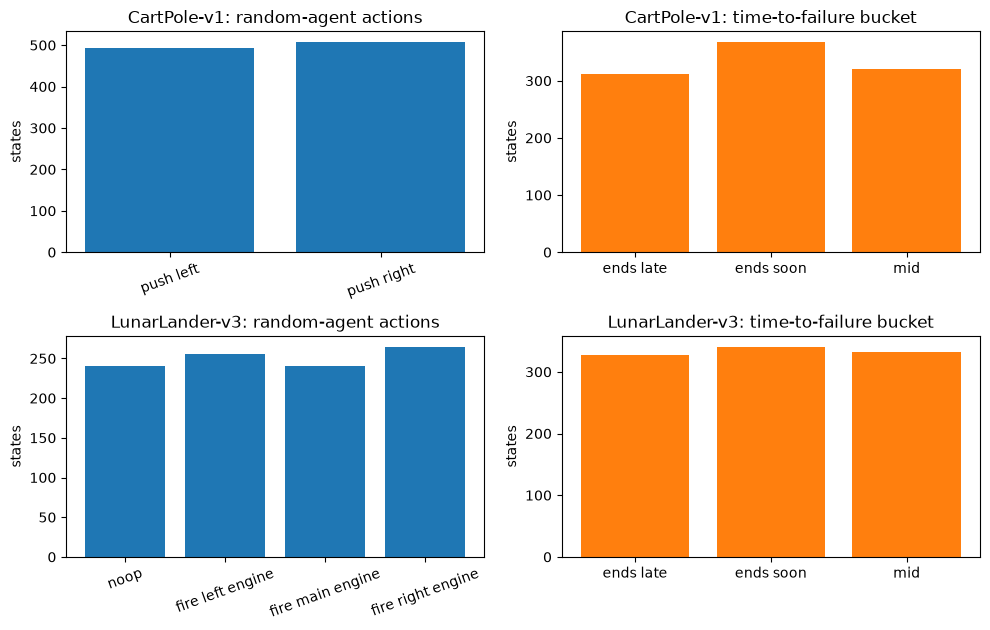

In [6]:
FEATURE_NAMES = {
    "CartPole-v1": ["cart position", "cart velocity", "pole angle", "pole angular velocity"],
    "LunarLander-v3": ["x", "y", "x velocity", "y velocity", "angle", "angular velocity", "left leg contact", "right leg contact"],
}
ACTION_NAMES = {
    "CartPole-v1": ["push left", "push right"],
    "LunarLander-v3": ["noop", "fire left engine", "fire main engine", "fire right engine"],
}
BANK = {e: collect_state_bank(e, N_BANK, seed=SEED + 1) for e in ACTIVE_ENVS}

for e in ACTIVE_ENVS:
    bk = BANK[e]
    print("=" * 100)
    print(e, "| state bank shape:", bk["raw"].shape, "| episodes:", len(np.unique(bk["episode"])))
    print("features :", FEATURE_NAMES[e])
    print("raw observation ranges:\n", pd.DataFrame(bk["raw"], columns=FEATURE_NAMES[e]).describe().loc[["min", "mean", "max"]].round(3).to_string())
    print("original action labels (random agent):", dict(zip(*np.unique(bk["action"], return_counts=True))))
    print("time-to-failure buckets            :", dict(zip(*np.unique(bk["bucket"], return_counts=True))))

fig, axes = plt.subplots(len(ACTIVE_ENVS), 2, figsize=(10, 3.2 * len(ACTIVE_ENVS)), squeeze=False)
for r, e in enumerate(ACTIVE_ENVS):
    bk = BANK[e]
    a, ca = np.unique(bk["action"], return_counts=True)
    axes[r, 0].bar([ACTION_NAMES[e][i] for i in a], ca, color="tab:blue"); axes[r, 0].set_title(f"{e}: random-agent actions"); axes[r, 0].tick_params(axis="x", rotation=20)
    b, cb = np.unique(bk["bucket"], return_counts=True)
    axes[r, 1].bar(b, cb, color="tab:orange"); axes[r, 1].set_title(f"{e}: time-to-failure bucket")
    for ax in axes[r]: ax.set_ylabel("states")
plt.tight_layout(); plt.show()

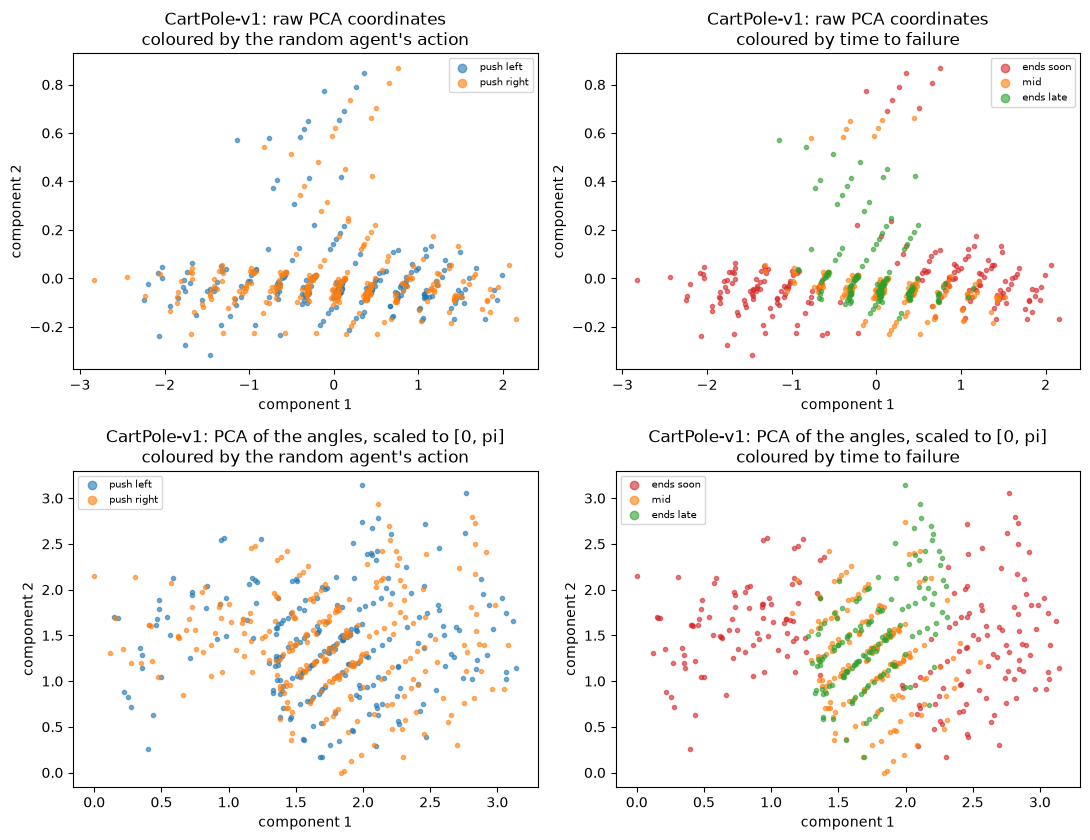

CartPole-v1: training half 484 states, explained variance of the 2 raw PCA axes: [0.963 0.032]


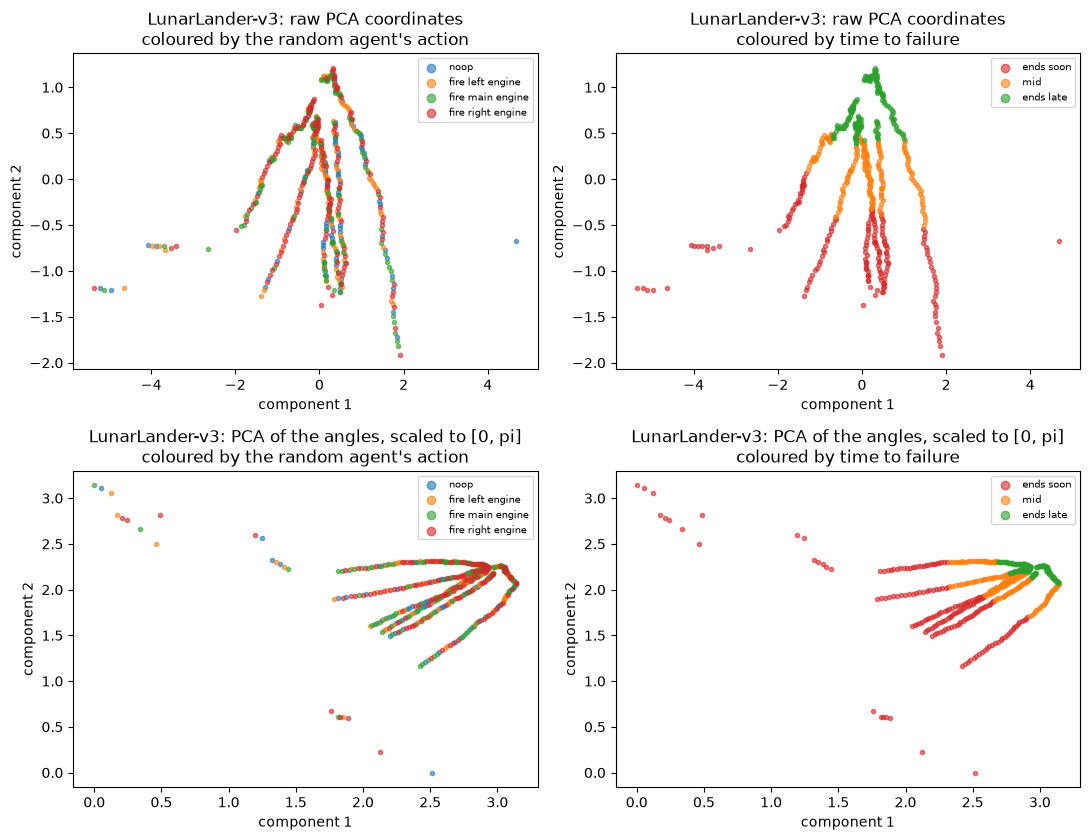

LunarLander-v3: training half 539 states, explained variance of the 2 raw PCA axes: [0.582 0.265]


In [7]:
BUCKET_COLORS = {"ends soon": "tab:red", "mid": "tab:orange", "ends late": "tab:green"}
for e in ACTIVE_ENVS:
    bk = BANK[e]
    train = bk["episode"] % 2 == 0                                   # even episodes = training half, odd = held out
    Xr_tr = bk["raw"][train]
    pca_raw = PCA(n_components=2, random_state=SEED).fit(Xr_tr)       # fitted on the training half only
    Z_raw = pca_raw.transform(Xr_tr)
    ang = bk["S"].numpy()                                           # observations as angles in [0, pi]
    pca_ang = PCA(n_components=2, random_state=SEED).fit(ang[train])
    mm = MinMaxScaler((0, np.pi)).fit(pca_ang.transform(ang[train]))
    Z_ang = mm.transform(pca_ang.transform(ang[train]))
    act, buck = bk["action"][train], bk["bucket"][train]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
    for row, (Z, name) in enumerate([(Z_raw, "raw PCA coordinates"), (Z_ang, "PCA of the angles, scaled to [0, pi]")]):
        for k, an in enumerate(ACTION_NAMES[e]):
            m = act == k
            axes[row, 0].scatter(Z[m, 0], Z[m, 1], s=9, alpha=.6, label=an)
        axes[row, 0].set_title(f"{e}: {name}\ncoloured by the random agent's action"); axes[row, 0].legend(fontsize=7, markerscale=2)
        for bname, col in BUCKET_COLORS.items():
            m = buck == bname
            axes[row, 1].scatter(Z[m, 0], Z[m, 1], s=9, alpha=.6, c=col, label=bname)
        axes[row, 1].set_title(f"{e}: {name}\ncoloured by time to failure"); axes[row, 1].legend(fontsize=7, markerscale=2)
        for ax in axes[row]: ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    plt.tight_layout(); plt.show()
    print(f"{e}: training half {train.sum()} states, explained variance of the 2 raw PCA axes: {pca_raw.explained_variance_ratio_.round(3)}")

**Reading the plots.** The random agent chooses its actions without looking at the state, so the action colours are
(correctly) intermixed: there is no "right" action visible in a single state of a random trajectory. The time-to-failure
colours show real structure: states shortly before the pole falls (CartPole) or the lander crashes sit at the edges of the
cloud. The second row is what the circuit actually sees: after the min-max step each qubit receives an angle in [0, pi].

## 3. Quantum Circuit Architecture

The circuit below is the **PennyLane QNode** of the paper's policy (Table 2), exactly the object whose outputs and
gradients the PyTorch simulator of section 1 reproduces. Layer l = (R_x, R_y, R_z on every qubit) -> (CZ ring closing at
(0, n-1)) -> (data re-upload R_x(lambda_q s_q)); after L layers comes one more rotation layer; then the readout
(CartPole: one global Z^(x6); LunarLander: four disjoint Z_{2a} Z_{2a+1}). The cell first asserts that the QNode and the
simulator agree, then draws and counts.

**Assumptions where the paper is silent.** The order inside the arbitrary rotation (R_z R_y R_x as an operator product, so R_x
is applied first); one trainable scale lambda per (layer, qubit); qubit q reads observation (q mod obs_dim); only the n_theta =
3 (L+1) n rotation angles count as "variational parameters" (the paper's n_theta excludes lambda), lambda and the per-action
weights w are trained honestly and are not touched by the attack.

In [8]:
def make_qnode(spec):
    """The PennyLane QNode of the paper's policy circuit (default.qubit, PyTorch interface)."""
    n, L, od = spec["n"], spec["L"], spec["obs_dim"]
    dev = qml.device("default.qubit", wires=n)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(s, theta, lam):
        for l in range(L):
            for q in range(n):                                   # arbitrary single-qubit rotation R_z R_y R_x
                qml.RX(theta[l, q, 0], wires=q)
                qml.RY(theta[l, q, 1], wires=q)
                qml.RZ(theta[l, q, 2], wires=q)
            for q in range(n):                                   # CZ ring closing at (0, n-1)
                qml.CZ(wires=[q, (q + 1) % n])
            for q in range(n):                                   # data re-uploading R_x(lambda * s)
                qml.RX(lam[l, q] * s[q % od], wires=q)
        for q in range(n):                                       # final rotation layer
            qml.RX(theta[L, q, 0], wires=q)
            qml.RY(theta[L, q, 1], wires=q)
            qml.RZ(theta[L, q, 2], wires=q)
        outs = []
        for g in spec["groups"]:
            obs = qml.PauliZ(g[0])
            for q in g[1:]:
                obs = obs @ qml.PauliZ(q)
            outs.append(qml.expval(obs))
        return outs

    return circuit


def check_equivalence(env_name, seed=0, n_states=3):
    """Assert that the torch simulator and the PennyLane QNode give the same <O_k> and the same d<O_k>/d theta."""
    spec = ENV_SPECS[env_name]
    pol = QPolicy(env_name, seed)
    qn = make_qnode(spec)
    g = torch.Generator().manual_seed(seed + 123)
    S = torch.rand(n_states, spec["obs_dim"], generator=g) * np.pi
    pol.lam.data = 0.5 + torch.rand_like(pol.lam, generator=g)
    max_dz = max_dg = 0.0
    for i in range(n_states):
        th = pol.theta.detach().clone().requires_grad_()
        lm = pol.lam.detach().clone().requires_grad_()
        z_pl = torch.stack(list(qn(S[i], th, lm)))
        Wl, Kf = pol.sim.layer_unitaries(pol.theta)
        z_sim = pol.sim.readout(Wl, Kf, pol.lam, S[i:i + 1])[0]
        max_dz = max(max_dz, float((z_pl - z_sim).abs().max()))
        # gradient of the sum of readouts w.r.t. theta and lambda
        g_pl = torch.autograd.grad(z_pl.sum(), [th, lm])
        g_sim = torch.autograd.grad(z_sim.sum(), [pol.theta, pol.lam])
        max_dg = max(max_dg, max(float((a - b).abs().max()) for a, b in zip(g_pl, g_sim)))
    assert max_dz < 1e-9 and max_dg < 1e-9, (max_dz, max_dg)
    return max_dz, max_dg

CartPole-v1: PyTorch simulator == PennyLane QNode  (max |d<O>| = 2.3e-15, max |d grad| = 1.1e-14)


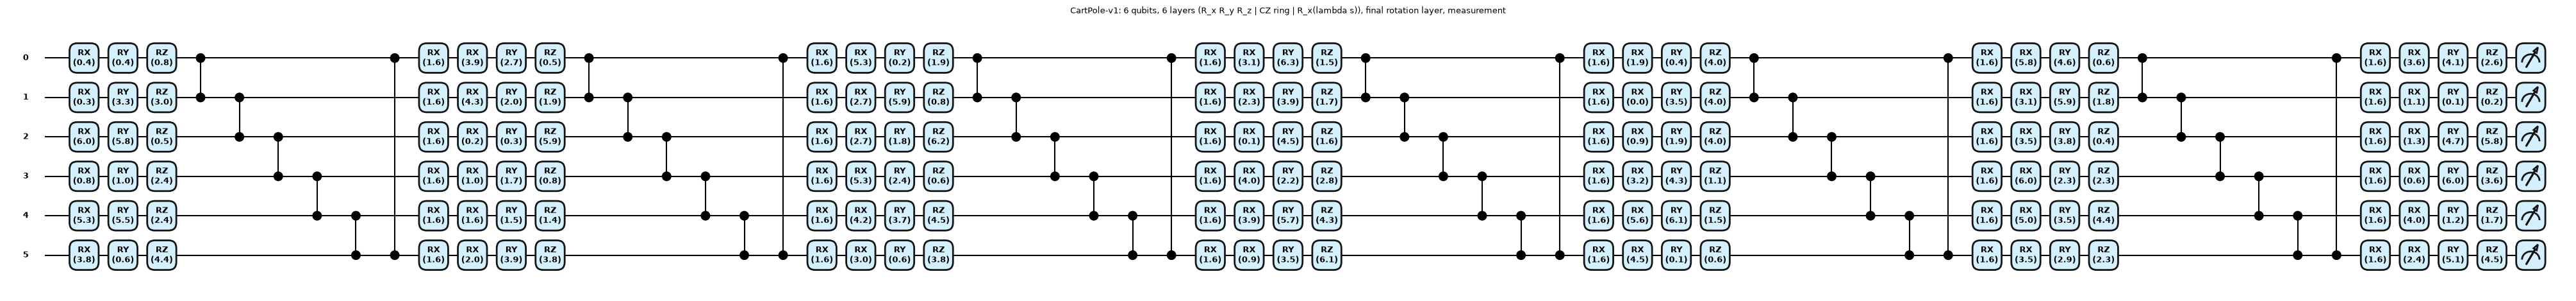

   qubits = 6 | circuit depth = 63 | gates = 198 | trainable parameters: theta 126 (= 3(L+1)n, attacked) + lambda 36 + w 2 = 164


LunarLander-v3: PyTorch simulator == PennyLane QNode  (max |d<O>| = 3.4e-15, max |d grad| = 1.1e-14)


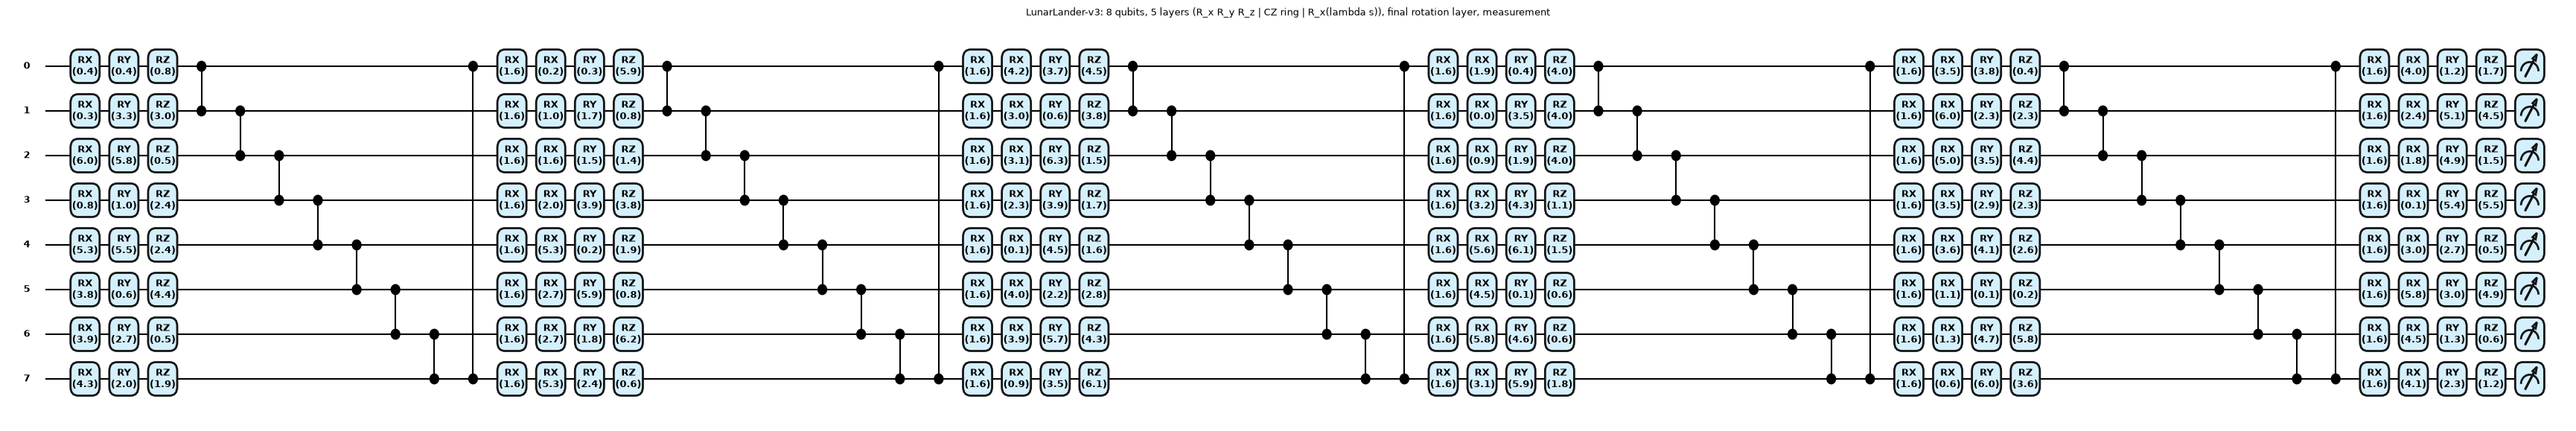

   qubits = 8 | circuit depth = 63 | gates = 224 | trainable parameters: theta 144 (= 3(L+1)n, attacked) + lambda 40 + w 4 = 188


In [9]:
import matplotlib.pyplot as plt
for e in ACTIVE_ENVS:
    spec = ENV_SPECS[e]
    dz, dg = check_equivalence(e, seed=SEED)            # asserts agreement to 1e-9
    print(f"{e}: PyTorch simulator == PennyLane QNode  (max |d<O>| = {dz:.1e}, max |d grad| = {dg:.1e})")
    qn = make_qnode(spec)
    pol0 = QPolicy(e, SEED)
    s0 = torch.full((spec["obs_dim"],), 0.5 * np.pi)
    th, lm = pol0.theta.detach(), pol0.lam.detach()
    fig, ax = qml.draw_mpl(qn, decimals=1, style="pennylane", fontsize=9)(s0, th, lm)
    fig.set_size_inches(min(40, 3.2 + 0.52 * 12 * spec["L"]), 0.55 * spec["n"] + 1.0)
    ax.set_title(f"{e}: {spec['n']} qubits, {spec['L']} layers (R_x R_y R_z | CZ ring | R_x(lambda s)), final rotation layer, measurement", fontsize=9)
    plt.show()
    res = qml.specs(qn)(s0, th, lm)["resources"]
    n_theta, n_lam, n_w = th.numel(), lm.numel(), len(spec["w_init"])
    print(f"   qubits = {spec['n']} | circuit depth = {res.depth} | gates = {res.num_gates} | "
          f"trainable parameters: theta {n_theta} (= 3(L+1)n, attacked) + lambda {n_lam} + w {n_w} = {n_theta + n_lam + n_w}")

## 4. REINFORCE, the compromised hand-off and QSignFlip

**Honest training.** One update collects a batch of `BATCH_EPS` episodes, computes the REINFORCE loss
L = -mean_t log pi(a_t|s_t) G_t (returns-to-go G_t with discount 0.99, normalised over the batch) and its gradient
g = grad_theta L. In a hybrid pipeline this is the tensor that the quantum backend hands to the classical optimiser.

**The compromised hand-off.** Between `loss.backward()` and `optimizer.step()` the function `qsignflip` (Algorithm 1) may
rewrite g. It estimates the target direction h on `M_TARGET` random batch states, scores each coordinate with
sigma_i = h_i g_i, and flips the signs of the k = round(beta n_theta) coordinates with the largest positive score. The code
asserts after every attack that |g_tilde| = |g| entrywise, so the norm seen by a monitor is unchanged.

**Controls and schedules.** `random_flip` flips k random coordinates. `always_on` attacks every update (budget
floor(rho T) with rho = 1). `momentum` attacks only when the last three values of the moving-average return strictly
increase, at most floor(rho T) times.

**Evaluation.** After training, the attacked and the clean policy (same seed, hence same initial parameters) are evaluated
on the state bank: ASRD (eq. 7) and Delta log P (eq. 8).

In [10]:
import numpy as np  # (re-imported so this cell can be run alone)
def qsignflip(g, h, beta):
    """Algorithm 1, steps 3-6: flip the signs of the k = round(beta * n_theta) coordinates with the largest
    positive signed-product score sigma_i = h_i * g_i.  |g_tilde| == |g| so the gradient norm is unchanged."""
    sigma = h * g
    k = int(round(beta * g.numel()))
    pos = torch.nonzero(sigma > 0).flatten()
    k_eff = min(k, pos.numel())
    g_t = g.clone()
    if k_eff > 0:
        top = pos[torch.topk(sigma[pos], k_eff).indices]
        g_t[top] = -g_t[top]
    return g_t, k_eff


def random_flip(g, beta, rng):
    """Matched-budget baseline: flip k coordinates chosen uniformly at random."""
    k = int(round(beta * g.numel()))
    g_t = g.clone()
    idx = torch.tensor(rng.choice(g.numel(), size=k, replace=False))
    g_t[idx] = -g_t[idx]
    return g_t, k


def discounted_returns(r, gamma):
    G, out = 0.0, np.zeros(len(r))
    for t in reversed(range(len(r))):
        G = r[t] + gamma * G
        out[t] = G
    return out


def run_episode(env, pol, rng, seed_reset, max_steps=1000):
    s, _ = env.reset(seed=seed_reset)
    S, A, R = [], [], []
    for _ in range(max_steps):
        sn = pol.sim.normalise(s)
        a = pol.act(sn, rng)
        S.append(sn.numpy())
        A.append(a)
        s, r, term, trunc, _ = env.step(a)
        R.append(r)
        if term or trunc:
            break
    return np.array(S), np.array(A), np.array(R)


def train_run(env_name, seed, mode="clean", beta=0.05, rho=1.0, a_star=0, N=None, R_star=None,
              batch_eps=5, lr_theta=0.02, lr_lam=0.05, lr_w=0.05, gamma=0.99, m_target=32,
              track_qfi=False, n_qfi=6, verbose=False):
    """REINFORCE on the data re-uploading VQC policy; the gradient of theta passes through the
    (possibly compromised) gradient-processing hook before the Adam optimiser sees it.
    mode in {'clean', 'always_on', 'momentum', 'random_flip'}."""
    spec = ENV_SPECS[env_name]
    N = N or spec["N"]
    R_star = R_star if R_star is not None else spec["R_star"]
    pol = QPolicy(env_name, seed)
    rng = np.random.default_rng(seed)
    atk_rng = np.random.default_rng(10_000 + seed)
    env = gym.make(env_name)
    opt = torch.optim.Adam([{"params": [pol.theta], "lr": lr_theta},
                            {"params": [pol.lam], "lr": lr_lam},
                            {"params": [pol.w], "lr": lr_w}])
    T = N // batch_eps                                   # maximum number of optimiser updates
    budget = int(np.floor(rho * T)) if mode != "clean" else 0
    ep_returns, ma_hist, log = [], [], []
    attacked_steps, flipped_total, ep_count, t0 = 0, 0, 0, time.time()
    for u in range(T):
        Sb, Ab, Gb, rets = [], [], [], []
        for _ in range(batch_eps):
            S, A, R = run_episode(env, pol, rng, seed_reset=int(rng.integers(1 << 30)))
            Sb.append(S); Ab.append(A); Gb.append(discounted_returns(R, gamma)); rets.append(R.sum())
            ep_count += 1
        ep_returns += rets
        S = torch.tensor(np.concatenate(Sb)); A = torch.tensor(np.concatenate(Ab)); G = np.concatenate(Gb)
        G = torch.tensor((G - G.mean()) / (G.std() + 1e-8))                    # CHOICE: batch-normalised returns
        lp_all, z = pol.log_probs(S)
        lp = lp_all.gather(1, A[:, None])[:, 0]
        loss = -(lp * G).mean()                                                # honest REINFORCE loss
        opt.zero_grad()
        loss.backward()
        g = pol.theta.grad.reshape(-1).clone()                                 # honest gradient at the hand-off
        ma = float(np.mean(ep_returns[-20:])); ma_hist.append(ma)
        # --------------- the compromised gradient-processing component ------------------
        attack_now = False
        if mode == "always_on":
            attack_now = attacked_steps < budget
        elif mode == "momentum":
            attack_now = (attacked_steps < budget and len(ma_hist) >= 3
                          and ma_hist[-3] < ma_hist[-2] < ma_hist[-1])         # three strictly increasing values
        elif mode == "random_flip":
            attack_now = attacked_steps < budget
        g_used = g
        if attack_now:
            if mode == "random_flip":
                g_used, k_eff = random_flip(g, beta, atk_rng)
            else:
                sub = torch.tensor(atk_rng.choice(len(S), size=min(m_target, len(S)), replace=False))
                lps, _ = pol.log_probs(S[sub])
                h = torch.autograd.grad(lps[:, a_star].mean(), pol.theta)[0].reshape(-1)    # target direction (eq. 3)
                g_used, k_eff = qsignflip(g, h, beta)
            attacked_steps += 1
            flipped_total += k_eff
            assert torch.allclose(g_used.abs(), g.abs())                      # magnitudes (and the norm) are preserved
        rec = dict(update=u, episodes=ep_count, ma_return=ma, grad_norm=float(g.norm()),
                   grad_norm_used=float(g_used.norm()), attacked=bool(attack_now))
        if track_qfi:
            rec.update(qfi_signal(pol, S, A, G, z.detach(), g_used.detach(), n_qfi, atk_rng))
        log.append(rec)
        pol.theta.grad = g_used.reshape(pol.theta.shape).clone()
        opt.step()
        pol.refresh()
        if verbose and u % 10 == 0:
            print(f"  upd {u:3d} ep {ep_count:4d}  MA20 return {ma:7.1f}  attacked={attacked_steps}")
        if ma >= R_star and len(ep_returns) >= 20:
            break
    env.close()
    return dict(policy=pol, log=log, ep_returns=ep_returns, episodes=ep_count, updates=len(log),
                attacked_steps=attacked_steps, flipped_total=flipped_total, final_ma=float(np.mean(ep_returns[-20:])),
                seconds=time.time() - t0, mode=mode, beta=beta, rho=rho, seed=seed)


# ---------------------- quantum-geometric detection signal (Section 7) --------------------------
def _apply_1q(v, M, q, n):
    """apply the 2x2 matrix M to qubit q of a state tensor v of shape (2,)*n + (extra,)."""
    return torch.movedim(torch.tensordot(M, v, dims=([1], [q])), 0, q)


@torch.no_grad()
def state_and_jacobian(sim, theta, lam, s):
    """exact |psi(theta, s)> (2^n,) and its Jacobian d|psi>/d theta (2^n, 3(L+1)n), column order = theta.reshape(-1).
    Forward sweep: the derivative columns of every layer are carried through the remaining layers
    (no autograd; ~100x faster than a generic Jacobian for this circuit)."""
    n, L, D = sim.n, sim.L, sim.D
    Wl, Kfin = sim.layer_unitaries(theta)
    U = sim._rot(theta)                                                           # (L+1, n, 2, 2)
    a, b, c = theta[..., 0], theta[..., 1], theta[..., 2]
    X = torch.tensor([[0, 1], [1, 0]], dtype=CDT); Y = torch.tensor([[0, -1j], [1j, 0]], dtype=CDT); Z = torch.tensor([[1, 0], [0, -1]], dtype=CDT)
    RX = sim._rot(torch.stack([a, 0 * a, 0 * a], -1)); RY = sim._rot(torch.stack([0 * b, b, 0 * b], -1)); RZ = sim._rot(torch.stack([0 * c, 0 * c, c], -1))
    dU = torch.stack([RZ @ RY @ (-0.5j * X) @ RX, RZ @ (-0.5j * Y) @ RY @ RX, (-0.5j * Z) @ RZ @ RY @ RX], dim=2)   # (L+1, n, 3, 2, 2)
    Sq = s[sim.col]
    psi = torch.zeros(D, dtype=CDT); psi[0] = 1.0                                 # |0...0>
    Dm = torch.zeros(D, 0, dtype=CDT)
    for l in range(L + 1):
        cols = []
        v0 = psi.reshape([2] * n + [1])
        for q in range(n):
            for j in range(3):
                v = v0
                for q2 in range(n):
                    v = _apply_1q(v, dU[l, q, j] if q2 == q else U[l, q2], q2, n)
                col = v.reshape(D)
                cols.append(col * self_cz(sim, l, L))
        new_cols = torch.stack(cols, dim=1)
        if l < L:
            Dm = Wl[l] @ Dm if Dm.shape[1] else Dm
            psi = Wl[l] @ psi
            Dm = torch.cat([Dm, new_cols], dim=1)
            phase = torch.exp(-0.5j * (sim.zs @ (lam[l] * Sq)))
            enc = lambda x: sim.Hn @ (phase.reshape(-1, *([1] * (x.dim() - 1))) * (sim.Hn @ x))
            psi = enc(psi); Dm = enc(Dm)
        else:
            Dm = Kfin @ Dm if Dm.shape[1] else Dm
            Dm = torch.cat([Dm, new_cols], dim=1)
            psi = Kfin @ psi
    return psi, Dm


def self_cz(sim, l, L):
    return sim.cz if l < L else torch.ones(sim.D, dtype=CDT)


def qfi_signal(pol, S, A, G, z, g_hat, n_states, rng, rtols=(1e-8, 1e-6, 1e-4)):
    """phi_t = C_t / B_t with C_t = g_hat^T Fbar^+ g_hat (eq. 10) and B_t = mean_n c_n^2 (1 - z_n^2) (eq. 11).
    Fbar is the QFI (eq. 9, with respect to theta) averaged over n_states batch states."""
    sim = pol.sim
    idx = rng.choice(len(S), size=min(n_states, len(S)), replace=False)
    P = pol.theta.numel()
    Fbar = torch.zeros(P, P)
    theta0 = pol.theta.detach()
    lam = pol.lam.detach()
    for i in idx:
        psi, Jc = state_and_jacobian(sim, theta0, lam, S[int(i)])
        Gm = Jc.conj().T @ Jc
        b = psi.conj() @ Jc                                                                 # <psi|d_j psi>
        F = 4 * (Gm - b.conj()[:, None] * b[None, :]).real
        Fbar += F / len(idx)
    ev, U = torch.linalg.eigh(0.5 * (Fbar + Fbar.T))
    out = {}
    # per-transition sensitivity c_n = dL_n / dz_n for L_n = -G_n log pi(a_n|s_n)  (z = readouts, shape (N, K))
    with torch.no_grad():
        lg = z * pol.w
        pr = torch.softmax(lg, -1)
        onehot = torch.nn.functional.one_hot(A, pr.shape[1]).double()
        dlogp_dlogit = onehot - pr                                                          # (N, n_actions)
        if z.shape[1] == 1:
            dlogp_dz = (dlogp_dlogit * pol.w).sum(1, keepdim=True)
        else:
            dlogp_dz = dlogp_dlogit * pol.w
        c = -(G[:, None] * dlogp_dz)                                                        # dL_n/dz_n
        Bt = float((c ** 2 * (1 - z ** 2)).sum(1).mean())
    for rt in rtols:
        keep = ev > rt * ev.max()
        coef = U[:, keep].T @ g_hat
        Ct = float((coef ** 2 / ev[keep]).sum())
        out[f"phi_{rt:g}"] = Ct / max(Bt, 1e-12)
    out["B_t"] = Bt
    out["qfi_rank"] = int((ev > 1e-6 * ev.max()).sum())
    return out

### 4.1 Checking the theory numerically: Proposition 1

Proposition 1 says that, for one SGD step of size eta, flipping the coordinates in I changes the average target
log-probability by 2 eta sum_{i in I} sigma_i plus a term of order eta^2. The cell below checks this on a freshly initialised
CartPole policy with a real batch of random-agent states: the ratio (measured change) / (predicted change) must tend to 1 as
eta -> 0. This is a test of the implementation of eq. 3-5, not of the paper's empirical claims.

In [11]:
e = "CartPole-v1"
pol = QPolicy(e, SEED)
bk = BANK[e]; S_b = bk["S"][:256]
gen = np.random.default_rng(SEED)
A_b = torch.tensor(gen.integers(0, 2, size=len(S_b)))
adv = torch.tensor(gen.standard_normal(len(S_b)))
lp, _ = pol.log_probs(S_b)
loss = -(lp.gather(1, A_b[:, None])[:, 0] * adv).mean()
g = torch.autograd.grad(loss, pol.theta)[0].reshape(-1)
Sm = S_b[:64]
lps, _ = pol.log_probs(Sm)
h = torch.autograd.grad(lps[:, A_STAR].mean(), pol.theta)[0].reshape(-1)
g_flip, k_eff = qsignflip(g, h, BETA)
I = torch.nonzero(g_flip != g).flatten()
sigma = h * g
def mean_logp(theta_flat):
    Wl, Kf = pol.sim.layer_unitaries(theta_flat.reshape(pol.theta.shape))
    z = pol.sim.readout(Wl, Kf, pol.lam.detach(), Sm)
    return torch.log_softmax(z * pol.w.detach(), -1)[:, A_STAR].mean()
th0 = pol.theta.detach().reshape(-1)
rows = []
for eta in [1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 1e-4]:
    measured = float(mean_logp(th0 - eta * g_flip) - mean_logp(th0 - eta * g))
    predicted = float(2 * eta * sigma[I].sum())
    rows.append(dict(eta=eta, measured=measured, predicted_2eta_sum_sigma=predicted, ratio=measured / predicted))
df_p1 = pd.DataFrame(rows); display(df_p1)
print(f"flipped {len(I)} of {g.numel()} coordinates, all with sigma > 0: {bool((sigma[I] > 0).all())}; norm unchanged: {float(g.norm()):.6f} -> {float(g_flip.norm()):.6f}")
assert abs(df_p1.ratio.iloc[-1] - 1) < 0.05

,eta,measured,predicted_2eta_sum_sigma,ratio
0,0.1000,3.838783e-04,3.832459e-04,1.001650
1,0.0300,1.150308e-04,1.149738e-04,1.000496
2,0.0100,3.833093e-05,3.832459e-05,1.000165
3,0.0030,1.149795e-05,1.149738e-05,1.000050
4,0.0010,3.832522e-06,3.832459e-06,1.000017
5,0.0001,3.832465e-07,3.832459e-07,1.000002


flipped 6 of 126 coordinates, all with sigma > 0: True; norm unchanged: 0.040671 -> 0.040671


## 5. Main experiment: QSignFlip against Random-Flip and the momentum schedule

For every environment and seed we train four policies from the same initial parameters: **clean**, **always-on QSignFlip**
(beta = 0.05, rho = 1), **Random-Flip** (same budget) and **momentum-triggered QSignFlip** (beta = 0.05, rho = 0.2). Training
stops early when the rolling 20-episode return reaches R*. Each run prints its wall-clock time. CartPole clean and always-on
runs also record the QFI detection signal of section 7 while they train.

In [12]:
RUNS = {}          # (env, mode, beta, rho, seed) -> result dict
def get_run(env_name, seed, mode, beta=BETA, rho=None, qfi=False):
    rho = rho if rho is not None else {"clean": 1.0, "always_on": RHO_ALWAYS, "random_flip": RHO_ALWAYS, "momentum": RHO_MOM}[mode]
    key = (env_name, mode, round(beta, 4) if mode != "clean" else 0.0, round(rho, 4) if mode != "clean" else 0.0, seed)
    if key not in RUNS:
        r = train_run(env_name, seed, mode=mode, beta=beta, rho=rho, a_star=A_STAR, N=N_EPISODES[env_name],
                      R_star=R_STAR[env_name], batch_eps=BATCH_EPS, m_target=M_TARGET, track_qfi=qfi, n_qfi=N_QFI)
        RUNS[key] = r
        print(f"  {env_name:15s} seed {seed} {mode:11s} beta={beta:<5} rho={rho:<4} -> {r['episodes']:4d} episodes, "
              f"{r['updates']:3d} updates, MA20 return {r['final_ma']:7.1f}, attacked {r['attacked_steps']:3d} steps / "
              f"{r['flipped_total']:4d} flips, {r['seconds']:6.1f} s", flush=True)
    return RUNS[key]

def clean_of(env_name, seed):
    return RUNS[(env_name, "clean", 0.0, 0.0, seed)]

t_main = time.time()
for e in ACTIVE_ENVS:
    for sd in SEEDS:
        qfi_on = (e == "CartPole-v1")
        get_run(e, sd, "clean", qfi=qfi_on)
        get_run(e, sd, "always_on", qfi=qfi_on)
        get_run(e, sd, "random_flip")
        get_run(e, sd, "momentum")
print(f"main grid finished in {(time.time() - t_main) / 60:.1f} min")

  CartPole-v1     seed 0 clean       beta=0.05  rho=1.0  ->  380 episodes,  76 updates, MA20 return   400.4, attacked   0 steps /    0 flips,  190.3 s


  CartPole-v1     seed 0 always_on   beta=0.05  rho=1.0  ->  500 episodes, 100 updates, MA20 return    85.7, attacked 100 steps /  600 flips,  234.1 s


  CartPole-v1     seed 0 random_flip beta=0.05  rho=1.0  ->  350 episodes,  70 updates, MA20 return   441.1, attacked  70 steps /  420 flips,   97.7 s


  CartPole-v1     seed 0 momentum    beta=0.05  rho=0.2  ->  490 episodes,  98 updates, MA20 return   406.4, attacked  20 steps /  120 flips,  190.1 s


  CartPole-v1     seed 1 clean       beta=0.05  rho=1.0  ->  500 episodes, 100 updates, MA20 return   290.1, attacked   0 steps /    0 flips,  272.4 s


...

  LunarLander-v3  seed 2 clean       beta=0.05  rho=1.0  ->  100 episodes,  20 updates, MA20 return  -178.5, attacked   0 steps /    0 flips,   66.2 s


  LunarLander-v3  seed 2 always_on   beta=0.05  rho=1.0  ->  100 episodes,  20 updates, MA20 return  -163.7, attacked  20 steps /  140 flips,   78.7 s


  LunarLander-v3  seed 2 random_flip beta=0.05  rho=1.0  ->  100 episodes,  20 updates, MA20 return  -145.8, attacked  20 steps /  140 flips,   58.6 s


  LunarLander-v3  seed 2 momentum    beta=0.05  rho=0.2  ->  100 episodes,  20 updates, MA20 return  -177.9, attacked   4 steps /   28 flips,   79.5 s


main grid finished in 50.8 min


dLogP          ASRD        dLogP_cp        ASRD_cp        MA20_return          clean_MA20        
                                       mean    std   mean    std     mean    std    mean    std        mean      std       mean     std
env            condition                                                                                                               
CartPole-v1    always_on (QSignFlip)  0.151  0.404  0.012  0.152   -0.009  0.565   0.065  0.301     193.933   94.583    313.700  77.578
               random_flip            0.033  0.263 -0.013  0.046    0.034  0.057  -0.006  0.080     305.750  141.816    313.700  77.578
               momentum (QSignFlip)   0.221  0.178  0.056  0.080   -0.017  0.476   0.015  0.312     310.200  165.845    313.700  77.578
LunarLander-v3 always_on (QSignFlip)  0.109  0.110  0.528  0.133    0.118  0.075   0.568  0.302    -166.139   15.169   -154.265  28.143
               random_flip            0.091  0.183  0.149  0.624    0.055  0.174   0.013  0.697    -147.693   15.216   -154.265  28.143
               momentum (QSignFlip)  -0.127  0.063 -0.146  0.166   -0.132  0.049  -0.264  0.283    -178.937   16.075   -154.265  28.143

,condition,env,seed,ASRD,dLogP,argmax_rate_atk,argmax_rate_clean,ASRD_cp,dLogP_cp,MA20_return,clean_MA20,episodes,attacked_steps,flips
0,always_on (QSignFlip),CartPole-v1,0,0.120,0.316,0.586,0.466,0.369,0.551,85.650,400.350,500,100,600
1,always_on (QSignFlip),CartPole-v1,1,-0.161,-0.310,0.281,0.442,-0.233,-0.578,260.400,290.050,500,100,600
2,always_on (QSignFlip),CartPole-v1,2,0.078,0.445,0.542,0.464,0.058,-0.001,235.750,250.700,500,100,600
3,random_flip,CartPole-v1,0,-0.018,-0.003,0.448,0.466,0.034,0.095,441.100,400.350,350,70,420
4,random_flip,CartPole-v1,1,0.036,-0.209,0.478,0.442,0.045,0.025,317.900,290.050,500,100,600
5,random_flip,CartPole-v1,2,-0.056,0.312,0.408,0.464,-0.098,-0.019,158.250,250.700,500,100,600
6,momentum (QSignFlip),CartPole-v1,0,0.010,0.017,0.476,0.466,-0.104,-0.316,406.450,400.350,490,20,120
7,momentum (QSignFlip),CartPole-v1,1,0.148,0.338,0.590,0.442,0.369,0.532,118.700,290.050,500,20,120
8,momentum (QSignFlip),CartPole-v1,2,0.010,0.310,0.474,0.464,-0.219,-0.266,405.450,250.700,365,20,120
9,always_on (QSignFlip),LunarLander-v3,0,0.393,0.183,0.732,0.339,0.258,0.133,-182.382,-160.916,100,20,140


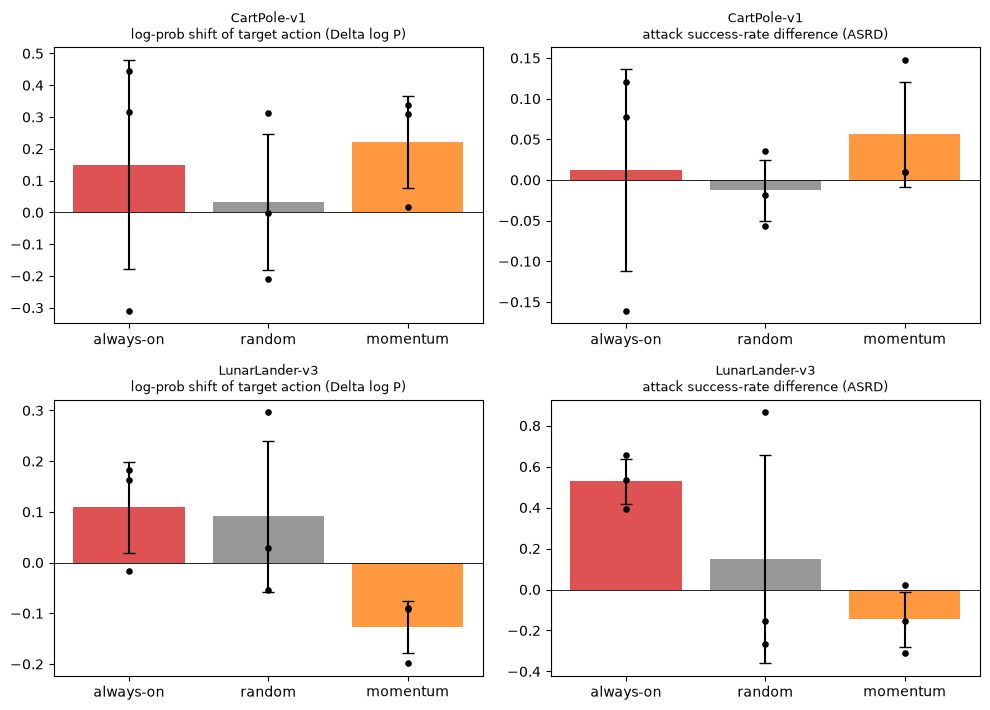

In [13]:
BANK_CP = {}
def eval_row(e, mode, beta, rho, sd):
    r = RUNS[(e, mode, beta, rho, sd)]
    m = policy_metrics(r["policy"], clean_of(e, sd)["policy"], BANK[e]["S"], A_STAR)
    if (e, sd) not in BANK_CP:        # secondary bank: states visited by the clean policy of this seed
        BANK_CP[(e, sd)] = collect_policy_states(e, clean_of(e, sd)["policy"], n_episodes=4 if e == "CartPole-v1" else 3, seed=SEED + 7 + sd)
    mc = policy_metrics(r["policy"], clean_of(e, sd)["policy"], BANK_CP[(e, sd)], A_STAR)
    return dict(env=e, seed=sd, **m, ASRD_cp=mc["ASRD"], dLogP_cp=mc["dLogP"], MA20_return=r["final_ma"], clean_MA20=clean_of(e, sd)["final_ma"], episodes=r["episodes"],
                attacked_steps=r["attacked_steps"], flips=r["flipped_total"])

COND = {"always_on (QSignFlip)": ("always_on", BETA, RHO_ALWAYS), "random_flip": ("random_flip", BETA, RHO_ALWAYS),
        "momentum (QSignFlip)": ("momentum", BETA, RHO_MOM)}
rows = []
for e in ACTIVE_ENVS:
    for name, (mode, b, rh) in COND.items():
        for sd in SEEDS:
            rows.append(dict(condition=name, **eval_row(e, mode, b, rh, sd)))
DF_MAIN = pd.DataFrame(rows)
summary = (DF_MAIN.groupby(["env", "condition"], sort=False)[["dLogP", "ASRD", "dLogP_cp", "ASRD_cp", "MA20_return", "clean_MA20"]]
           .agg(["mean", "std"]).round(3))
display(summary)
display(DF_MAIN.round(3))

fig, axes = plt.subplots(len(ACTIVE_ENVS), 2, figsize=(10, 3.6 * len(ACTIVE_ENVS)), squeeze=False)
cols = {"always_on (QSignFlip)": "tab:red", "random_flip": "tab:gray", "momentum (QSignFlip)": "tab:orange"}
for r_, e in enumerate(ACTIVE_ENVS):
    for c_, (metric, lab) in enumerate([("dLogP", "log-prob shift of target action (Delta log P)"), ("ASRD", "attack success-rate difference (ASRD)")]):
        ax = axes[r_, c_]
        for i, name in enumerate(COND):
            v = DF_MAIN[(DF_MAIN.env == e) & (DF_MAIN.condition == name)][metric].values
            ax.bar(i, v.mean(), yerr=v.std() if len(v) > 1 else 0, color=cols[name], alpha=.8, capsize=4)
            ax.scatter([i] * len(v), v, color="k", s=14, zorder=3)
        ax.axhline(0, color="k", lw=.6); ax.set_xticks(range(3)); ax.set_xticklabels(["always-on", "random", "momentum"])
        ax.set_title(f"{e}\n{lab}", fontsize=9)
plt.tight_layout(); plt.show()

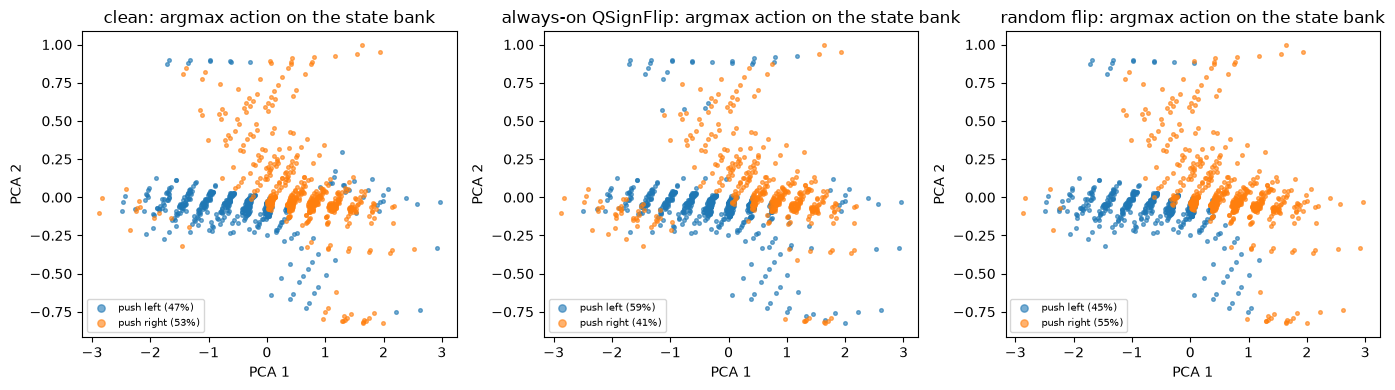

In [14]:
# What the attack does to the policy: the same real states, coloured by the action each policy would pick (CartPole, first seed).
e, sd = "CartPole-v1", SEEDS[0]
if e in ACTIVE_ENVS:
    bk = BANK[e]; pca = PCA(2, random_state=SEED).fit(bk["raw"][bk["episode"] % 2 == 0]); Z = pca.transform(bk["raw"])
    pols = {"clean": clean_of(e, sd)["policy"], "always-on QSignFlip": RUNS[(e, "always_on", BETA, RHO_ALWAYS, sd)]["policy"],
            "random flip": RUNS[(e, "random_flip", BETA, RHO_ALWAYS, sd)]["policy"]}
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (nm, p) in zip(axes, pols.items()):
        am = p.probs(bk["S"]).argmax(1).numpy()
        for k, an in enumerate(ACTION_NAMES[e]):
            ax.scatter(Z[am == k, 0], Z[am == k, 1], s=7, alpha=.6, label=f"{an} ({(am == k).mean():.0%})")
        ax.set_title(f"{nm}: argmax action on the state bank"); ax.legend(fontsize=7, markerscale=2); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")
    plt.tight_layout(); plt.show()

## 6. Budget sweeps (paper Fig. 2b)

*Coordinate budget* beta (always-on) and *rate budget* rho (momentum-triggered, beta = 0.05), on CartPole. The runs that
coincide with the main experiment are reused. For the momentum schedule the real number of attacked steps is limited by how
often three strictly increasing moving-average values occur, so the table also lists the attacked steps.

  CartPole-v1     seed 0 always_on   beta=0.01  rho=1.0  ->  500 episodes, 100 updates, MA20 return   126.9, attacked 100 steps /  100 flips,  113.1 s


  CartPole-v1     seed 1 always_on   beta=0.01  rho=1.0  ->  500 episodes, 100 updates, MA20 return   269.9, attacked 100 steps /  100 flips,  137.6 s


  CartPole-v1     seed 0 always_on   beta=0.1   rho=1.0  ->  500 episodes, 100 updates, MA20 return   132.9, attacked 100 steps / 1300 flips,   87.5 s


  CartPole-v1     seed 1 always_on   beta=0.1   rho=1.0  ->  500 episodes, 100 updates, MA20 return    82.2, attacked 100 steps / 1300 flips,   76.8 s


  CartPole-v1     seed 0 always_on   beta=0.2   rho=1.0  ->  500 episodes, 100 updates, MA20 return   387.2, attacked 100 steps / 2500 flips,   69.1 s


...

  CartPole-v1     seed 1 momentum    beta=0.05  rho=0.5  ->  415 episodes,  83 updates, MA20 return   405.9, attacked  42 steps /  252 flips,  106.8 s


  CartPole-v1     seed 0 momentum    beta=0.05  rho=1.0  ->  395 episodes,  79 updates, MA20 return   410.4, attacked  32 steps /  192 flips,   90.1 s


  CartPole-v1     seed 1 momentum    beta=0.05  rho=1.0  ->  415 episodes,  83 updates, MA20 return   405.9, attacked  42 steps /  252 flips,  109.7 s


sweeps finished in 18.6 min


dLogP          ASRD        attacked_steps          flips        
                         mean    std   mean    std           mean    std    mean     std
sweep            value                                                                  
beta (always-on) 0.01   0.013  0.034 -0.022  0.003          100.0  0.000   100.0   0.000
                 0.05   0.003  0.443 -0.021  0.199          100.0  0.000   600.0   0.000
                 0.10   0.203  0.051  0.119  0.040          100.0  0.000  1300.0   0.000
                 0.20   0.216  0.181  0.041  0.054          100.0  0.000  2500.0   0.000
rho (momentum)   0.10  -0.125  0.262 -0.085  0.045           10.0  0.000    60.0   0.000
                 0.20   0.177  0.227  0.079  0.098           20.0  0.000   120.0   0.000
                 0.50  -0.115  0.023 -0.012  0.004           37.0  7.071   222.0  42.426
                 1.00  -0.115  0.023 -0.012  0.004           37.0  7.071   222.0  42.426

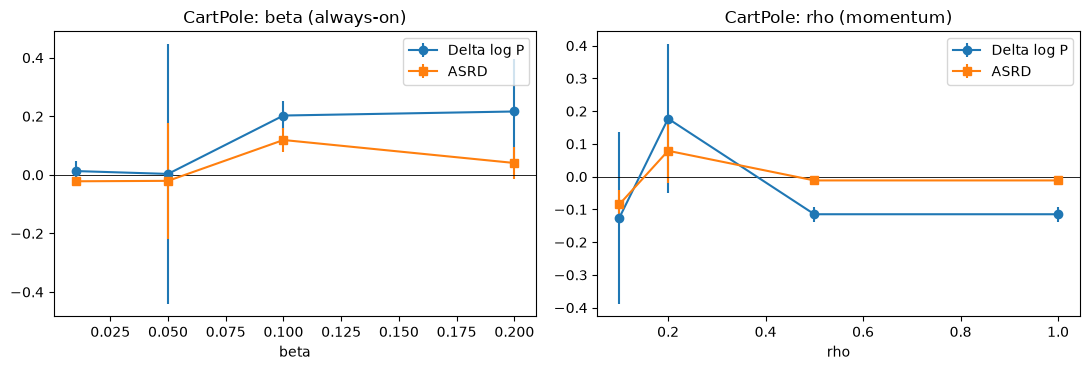

In [15]:
t_sw = time.time()
SW = []
if "CartPole-v1" in ACTIVE_ENVS:
    e = "CartPole-v1"
    for b in BETA_GRID:
        for sd in SWEEP_SEEDS:
            get_run(e, sd, "always_on", beta=b, rho=RHO_ALWAYS, qfi=(abs(b - BETA) < 1e-9))
            SW.append(dict(sweep="beta (always-on)", value=b, **eval_row(e, "always_on", round(b, 4), RHO_ALWAYS, sd)))
    for rh in RHO_GRID:
        for sd in SWEEP_SEEDS:
            get_run(e, sd, "momentum", beta=BETA, rho=rh)
            SW.append(dict(sweep="rho (momentum)", value=rh, **eval_row(e, "momentum", BETA, round(rh, 4), sd)))
print(f"sweeps finished in {(time.time() - t_sw) / 60:.1f} min")
DF_SW = pd.DataFrame(SW)
if len(DF_SW):
    tab = DF_SW.groupby(["sweep", "value"])[["dLogP", "ASRD", "attacked_steps", "flips"]].agg(["mean", "std"]).round(3)
    display(tab)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, sweep in zip(axes, ["beta (always-on)", "rho (momentum)"]):
        d = DF_SW[DF_SW.sweep == sweep].groupby("value")[["dLogP", "ASRD"]].agg(["mean", "std"])
        ax.errorbar(d.index, d[("dLogP", "mean")], yerr=d[("dLogP", "std")].fillna(0), marker="o", label="Delta log P")
        ax.errorbar(d.index, d[("ASRD", "mean")], yerr=d[("ASRD", "std")].fillna(0), marker="s", label="ASRD")
        ax.axhline(0, color="k", lw=.6); ax.set_xlabel(sweep.split()[0]); ax.set_title(f"CartPole: {sweep}"); ax.legend()
    plt.tight_layout(); plt.show()

## 7. Towards a quantum-geometric defence (paper Sec. 7)

A norm monitor cannot see QSignFlip, because |g_tilde| = |g|. The paper proposes to look at the *direction* of the update
through the geometry of the victim's quantum states instead.

* The quantum Fisher information (QFI) of the policy state |psi(theta, s)> with respect to theta (eq. 9):
  F_ij = 4 Re[<d_i psi|d_j psi> - <d_i psi|psi><psi|d_j psi>], averaged over `N_QFI` states of the current batch.
* C_t = g_hat^T F^+ g_hat (eq. 10), where g_hat is the gradient the optimiser actually receives and F^+ the pseudo-inverse
  (relative eigenvalue cut-off 1e-6, `# CHOICE`; 1e-8 and 1e-4 are reported as a sensitivity check).
* B_t = mean_n c_n^2 (1 - z_n^2) (eq. 11) with c_n = dL_n/dz_n the sensitivity of the per-transition loss to the readout
  z_n; and the consistency signal phi_t = C_t / B_t.

The signal is computed at every update of the CartPole clean and always-on runs (the rows `phi_*` of their logs). The length-5
moving average phi^(5) is then compared across the two conditions: mean shift, ROC curve, AUC and the true-positive rate at
a 5 % false-alarm rate.

,cutoff,delta_phi,AUC,TPR_at_5pct_FPR,clean_mean,attacked_mean,n_clean,n_attacked,qfi_rank
0,1e-06,1.045,0.983,0.890,0.007,1.052,276,300,120
1,1e-08,2.249,0.984,0.903,0.007,2.256,276,300,120
2,0.0001,0.048,0.967,0.840,0.005,0.054,276,300,120


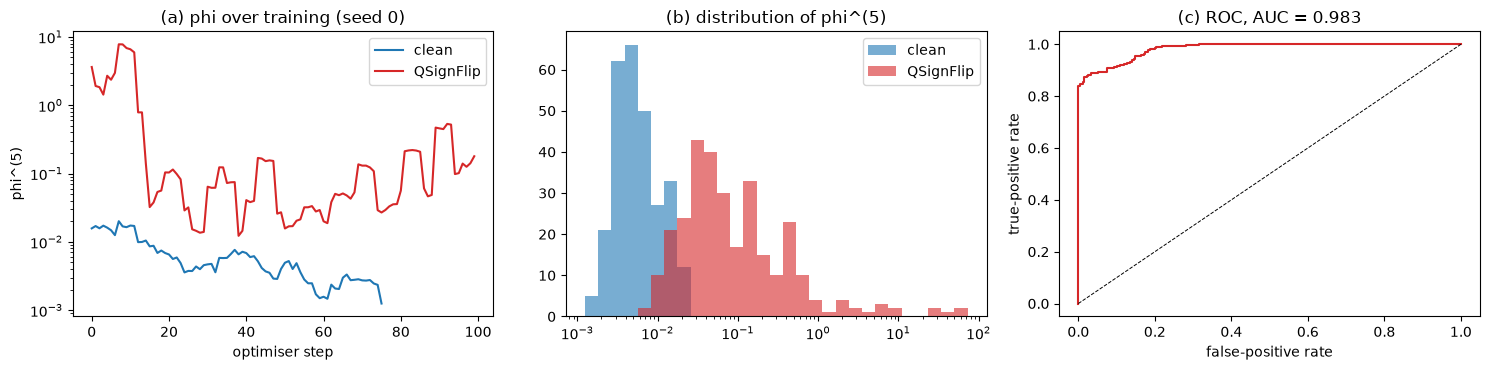

gradient norm seen by the optimiser, honest vs used (always-on run): max |difference| = 0.0


In [16]:
def phi_frame(env_name, mode, key_phi, win=5):
    out = []
    for sd in SEEDS:
        k = (env_name, mode, 0.0 if mode == "clean" else round(BETA, 4), 0.0 if mode == "clean" else round(RHO_ALWAYS, 4), sd)
        d = pd.DataFrame(RUNS[k]["log"])
        d["phi"] = d[key_phi]
        d["phi_ma"] = d["phi"].rolling(win, min_periods=1).mean()
        d["seed"] = sd; d["cond"] = mode
        out.append(d)
    return pd.concat(out, ignore_index=True)

DEF = {}
if "CartPole-v1" in ACTIVE_ENVS:
    e = "CartPole-v1"
    rows = []
    for key_phi in ["phi_1e-06", "phi_1e-08", "phi_0.0001"]:
        dc, da = phi_frame(e, "clean", key_phi), phi_frame(e, "always_on", key_phi)
        y = np.r_[np.zeros(len(dc)), np.ones(len(da))]; sc = np.r_[dc.phi_ma.values, da.phi_ma.values]
        fpr, tpr, _ = roc_curve(y, sc)
        rows.append(dict(cutoff=key_phi.replace("phi_", ""), delta_phi=da.phi_ma.mean() - dc.phi_ma.mean(),
                         AUC=roc_auc_score(y, sc), TPR_at_5pct_FPR=float(np.interp(0.05, fpr, tpr)),
                         clean_mean=dc.phi_ma.mean(), attacked_mean=da.phi_ma.mean(), n_clean=len(dc), n_attacked=len(da),
                         qfi_rank=int(da["qfi_rank"].median())))
        DEF[key_phi] = (dc, da, fpr, tpr)
    DF_DEF = pd.DataFrame(rows); display(DF_DEF.round(3))
    dc, da, fpr, tpr = DEF["phi_1e-06"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for sd in SEEDS[:1]:
        axes[0].plot(dc[dc.seed == sd].phi_ma.values, label="clean", color="tab:blue")
        axes[0].plot(da[da.seed == sd].phi_ma.values, label="QSignFlip", color="tab:red")
    axes[0].set_yscale("log"); axes[0].set_xlabel("optimiser step"); axes[0].set_ylabel("phi^(5)"); axes[0].set_title(f"(a) phi over training (seed {SEEDS[0]})"); axes[0].legend()
    bins = np.logspace(np.log10(max(min(dc.phi_ma.min(), da.phi_ma.min()), 1e-12)), np.log10(max(dc.phi_ma.max(), da.phi_ma.max())), 30)
    axes[1].hist(dc.phi_ma, bins=bins, alpha=.6, label="clean"); axes[1].hist(da.phi_ma, bins=bins, alpha=.6, label="QSignFlip", color="tab:red")
    axes[1].set_xscale("log"); axes[1].set_title("(b) distribution of phi^(5)"); axes[1].legend()
    axes[2].plot(fpr, tpr, color="tab:red"); axes[2].plot([0, 1], [0, 1], "k--", lw=.7)
    axes[2].set_xlabel("false-positive rate"); axes[2].set_ylabel("true-positive rate"); axes[2].set_title(f"(c) ROC, AUC = {roc_auc_score(np.r_[np.zeros(len(dc)), np.ones(len(da))], np.r_[dc.phi_ma, da.phi_ma]):.3f}")
    plt.tight_layout(); plt.show()
    # the norm monitor the paper says is blind:
    gn = pd.concat([pd.DataFrame(RUNS[("CartPole-v1", m, 0.0 if m == "clean" else round(BETA, 4), 0.0 if m == "clean" else round(RHO_ALWAYS, 4), SEEDS[0])]["log"]).assign(cond=m) for m in ("clean", "always_on")])
    print("gradient norm seen by the optimiser, honest vs used (always-on run): max |difference| =",
          float((gn[gn.cond == "always_on"].grad_norm - gn[gn.cond == "always_on"].grad_norm_used).abs().max()))

## 8. Paper versus this notebook

In [17]:
def verdict(paper, ours, tol, kind="abs"):
    if ours is None or not np.isfinite(ours): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    return f"exceeded (+{ours - paper:.3f})" if ours > paper else f"not reached ({ours - paper:+.3f})"

def stat(env, cond, metric):
    d = DF_MAIN[(DF_MAIN.env == env) & (DF_MAIN.condition == cond)][metric]
    return float(d.mean()) if len(d) else None

rows = []
def add(claim, paper_txt, ours_txt, v):
    rows.append(dict(claim=claim, paper=paper_txt, notebook=ours_txt, verdict=v))

for env, pv_logp, pv_asrd in [("LunarLander-v3", 0.24, 0.54), ("CartPole-v1", 0.11, 0.25)]:
    if env not in ACTIVE_ENVS:
        add(f"{env}: always-on dLogP / ASRD", f"{pv_logp} / {pv_asrd}", "environment not run", "cannot be checked"); continue
    lp, asr = stat(env, "always_on (QSignFlip)", "dLogP"), stat(env, "always_on (QSignFlip)", "ASRD")
    note = "" if env == "CartPole-v1" or N_EPISODES[env] >= 5500 else f" (only {N_EPISODES[env]} of 5500 episodes)"
    add(f"{env}: always-on dLogP", f"+{pv_logp}", f"{lp:+.3f}{note}", verdict(pv_logp, lp, 0.02))
    add(f"{env}: always-on ASRD (argmax shift)", f"+{pv_asrd * 100:.0f} pp", f"{asr * 100:+.1f} pp{note}", verdict(pv_asrd, asr, 0.05))
    rl, rs = stat(env, "random_flip", "dLogP"), stat(env, "random_flip", "ASRD")
    add(f"{env}: QSignFlip beats Random-Flip (dLogP)", "yes", f"{lp:+.3f} vs {rl:+.3f}", "reproduced" if lp > rl else "not reached")
    ml = stat(env, "momentum (QSignFlip)", "dLogP")
    inter = (rl <= ml <= lp) if None not in (rl, ml, lp) else False
    add(f"{env}: momentum is between random and always-on (dLogP)", "intermediate", f"random {rl:+.3f} | momentum {ml:+.3f} | always-on {lp:+.3f}", "reproduced" if inter else "not reached")
rl_ll = stat("LunarLander-v3", "random_flip", "dLogP") if "LunarLander-v3" in ACTIVE_ENVS else None
add("LunarLander-v3: Random-Flip dLogP", "0.002 (negligible)", "n/a" if rl_ll is None else f"{rl_ll:+.3f}", "cannot be checked" if rl_ll is None else verdict(0.002, rl_ll, 0.02))

if len(DF_SW):
    s = DF_SW[DF_SW.sweep == "beta (always-on)"].groupby("value").dLogP.mean()
    if len(s) >= 2 and s.iloc[0] > 0:
        ratio = s.iloc[-1] / s.iloc[0] if s.iloc[0] != 0 else np.nan
        add(f"beta sweep: dLogP(beta={s.index[-1]}) / dLogP(beta={s.index[0]})", "3.4x for a ten-fold budget", f"{ratio:.2f}x for a {s.index[-1] / s.index[0]:.0f}-fold budget", "cannot be checked" if not np.isfinite(ratio) else verdict(3.4, ratio, 1.0))
    else:
        add("beta sweep: dLogP growth with budget", "3.4x for a ten-fold budget", f"dLogP at smallest beta = {s.iloc[0]:+.3f}" if len(s) else "n/a", "cannot be checked")
    s2 = DF_SW[DF_SW.sweep == "rho (momentum)"].groupby("value").dLogP.mean()
    add("rho sweep: near zero until rho = 0.3, then about 3x larger", "yes", ", ".join(f"rho={k}: {v:+.3f}" for k, v in s2.items()), "cannot be checked (grid too coarse)" if len(s2) < 3 else ("reproduced" if (s2.iloc[-1] > 2 * abs(s2.iloc[0]) and s2.iloc[0] < 0.03) else "not reached"))

add("gradient norm unchanged by the attack", "exactly", "asserted after every attacked step (|g~| == |g|)", "reproduced")
add("Proposition 1 (first-order gain 2 eta sum sigma)", "analytic", f"ratio measured/predicted = {df_p1.ratio.iloc[-1]:.3f} at eta = 1e-4", "reproduced" if abs(df_p1.ratio.iloc[-1] - 1) < 0.05 else "not reached")
if DEF:
    d = DF_DEF[DF_DEF.cutoff == "1e-06"].iloc[0]
    add("QFI signal: mean shift of phi^(5)", "12.16", f"{d.delta_phi:.2f}", "cannot be checked (scale depends on the unstated normalisation of B_t)")
    add("QFI signal: AUC", "0.797", f"{d.AUC:.3f}", verdict(0.797, d.AUC, 0.05))
    add("QFI signal: TPR at 5% false alarms", "about 1/3", f"{d.TPR_at_5pct_FPR:.2f}", verdict(1 / 3, d.TPR_at_5pct_FPR, 0.10))
cl = DF_MAIN[DF_MAIN.env == "CartPole-v1"]
if len(cl):
    add("clean CartPole policy reaches R* = 400 within 500 episodes", "yes", f"clean MA20 return {np.mean([clean_of('CartPole-v1', sd)['final_ma'] for sd in SEEDS]):.0f} after "
        f"{np.mean([clean_of('CartPole-v1', sd)['episodes'] for sd in SEEDS]):.0f} episodes (budget {N_EPISODES['CartPole-v1']})",
        "reproduced" if np.mean([clean_of('CartPole-v1', sd)['final_ma'] for sd in SEEDS]) >= 400 else "not reached")
DF_CMP = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(DF_CMP)

,claim,paper,notebook,verdict
0,LunarLander-v3: always-on dLogP,+0.24,+0.109 (only 100 of 5500 episodes),not reached (-0.131)
1,LunarLander-v3: always-on ASRD (argmax shift),+54 pp,+52.8 pp (only 100 of 5500 episodes),reproduced
2,LunarLander-v3: QSignFlip beats Random-Flip (dLogP),yes,+0.109 vs +0.091,reproduced
3,LunarLander-v3: momentum is between random and always-on (dLogP),intermediate,random +0.091 | momentum -0.127 | always-on +0.109,not reached
4,CartPole-v1: always-on dLogP,+0.11,+0.151,exceeded (+0.041)
5,CartPole-v1: always-on ASRD (argmax shift),+25 pp,+1.2 pp,not reached (-0.238)
6,CartPole-v1: QSignFlip beats Random-Flip (dLogP),yes,+0.151 vs +0.033,reproduced
7,CartPole-v1: momentum is between random and always-on (dLogP),intermediate,random +0.033 | momentum +0.221 | always-on +0.151,not reached
8,LunarLander-v3: Random-Flip dLogP,0.002 (negligible),+0.091,exceeded (+0.089)
9,beta sweep: dLogP(beta=0.2) / dLogP(beta=0.01),3.4x for a ten-fold budget,16.72x for a 20-fold budget,exceeded (+13.321)


## Reading the paper critically

**What the experiments can and cannot show.** The mechanism is real and the notebook confirms the parts that are
mathematics: the flip preserves every magnitude and the norm, the score sigma_i = h_i g_i predicts the first-order gain
(Proposition 1, ratio 1.000 above), and top-k scoring is the right choice for that first-order gain. How much a *trained*
policy moves is an empirical question that depends on unstated hyper-parameters (optimiser, learning rates, batch size, how
the fixed state bank is built, the target action), so the size of the effect in the paper is not guaranteed to carry over.

**Noise dominates the CartPole numbers.** Clean and attacked runs share only their initial parameters; after the first
update the roll-outs differ, so the clean-vs-attacked difference contains ordinary reinforcement-learning variance. In the
committed run the per-seed Delta log P of always-on QSignFlip on CartPole is +0.32, -0.31 and +0.45 (mean +0.15, standard
deviation 0.40) and that of Random-Flip -0.00, -0.21 and +0.31; the target-action argmax rate on the random-agent state bank
moves by only about +1 percentage point (paper: +25). With three seeds, "QSignFlip beats Random-Flip" is a statement about
means that the seed spread does not support. The sweeps (two seeds) are noisier still: the momentum schedule gives identical
runs for rho = 0.5 and 1.0 because the trigger (three strictly increasing moving-average values) caps the attacked steps at
about 37, which is the paper's remark that rho is limited by the trigger frequency.

**LunarLander is the clearer case.** After only 100 of the paper's 5,500 episodes, always-on QSignFlip raises the argmax rate of
the target action by +53 pp (standard deviation 13 pp over three seeds; paper +54 pp) while the log-probability shift
(+0.11, paper +0.24) is about half. But the policies are barely trained at this budget, and Random-Flip also swings
wildly (mean +15 pp, one seed +87 pp), so the controls are not clean either. A faithful test of the paper's 5,500-episode
setting needs hours of CPU time per run.

**Early stopping couples the attack to the task.** Training stops when the rolling return reaches R*, so an attack that
pushes the policy towards a fixed action also slows its progress, and the run lengths of clean and attacked policies differ
(clean CartPole policies in the committed run needed 380, 500 and 500 episodes and reached an average rolling return of 314;
always-on QSignFlip reached 194). The paper's remark that the attack "does not guarantee policy-level stealth under
task-performance evaluation" is visible in the `MA20_return` columns.

**The defence is a first step.** In this notebook the QFI signal separates attacked from clean updates better than in the
paper (AUC 0.98 against 0.797), but the comparison pools update steps of three runs, clean runs stop earlier than attacked
ones, phi_t depends on choices the paper leaves open (QFI cut-off, number of averaged states, normalisation of B_t), and the
detector is evaluated against a non-adaptive attacker. An attacker aware of the QFI check could choose coordinates that keep
phi_t unchanged; the paper itself lists this, noiseless simulation and two control tasks as limitations.

**Threat model.** The attack needs a compromised component at the hand-off (for example a gradient-monitoring plugin
distributed through PyPI). Pinning dependencies, verifying hashes and signing plugins are cheaper defences than a QFI
monitor, and a norm monitor is insufficient by construction.

## Exercises

1. **Another target.** Set `A_STAR = 1` in the configuration cell and rerun the main experiment. Is the effect symmetric for
   the two CartPole actions?
2. **Optimiser.** Replace Adam by plain SGD in `train_run` (Proposition 1 is stated for SGD). Does the measured shift get
   closer to the prediction 2 eta sum sigma?
3. **Adaptive attacker.** Add a constraint to `qsignflip` that only flips coordinates for which the QFI-weighted response
   phi_t does not grow. How much of the attack success survives?
4. **Hand-off between circuit and optimiser.** The attack only touches theta. Let it flip the input scales lambda as well
   (they are also trained from the same hand-off). Is the policy more or less sensitive to them?
5. **Detection threshold.** Plot the ROC curve of the plain gradient norm (column `grad_norm` of the run logs) and compare it
   with the QFI signal. What does the AUC of the norm look like when the attack is active at every step?